Video Link - https://drive.google.com/file/d/1fdc3uGn7P69L_kSnwWgwIfKLpXtgw3kl/view?usp=sharing

**Assignment 3**

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # running locally: data is read from ./data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
"""First I import all the important libraries such as pandas/numpy/matplotlib etc. and analyze how the data looks
like such as - no. of columns/no. of rows type of data in each column after loadimg the dataset"""

'First I import all the important libraries such as pandas/numpy/matplotlib etc. and analyze how the data looks\nlike such as - no. of columns/no. of rows type of data in each column after loadimg the dataset'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('data/bank.csv')

In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [ ]:
df.shape

(11162, 17)

In [ ]:
# describe df numerical columns
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [ ]:
def display_unique_values(df):

  for col in df.select_dtypes(include='object').columns:
    print(f"Column: {col}")
    unique_values = df[col].unique()

    if len(unique_values) <= 20:
      print(f"Unique values: {', '.join(map(str, unique_values))}")
    else:
      print(f"Number of unique values: {len(unique_values)}")
      print("Sample unique values:", ', '.join(map(str, unique_values[:20])), "...")
    print("---")

display_unique_values(df)

Column: job
Unique values: admin., technician, services, management, retired, blue-collar, unemployed, entrepreneur, housemaid, unknown, self-employed, student
---
Column: marital
Unique values: married, single, divorced
---
Column: education
Unique values: secondary, tertiary, primary, unknown
---
Column: default
Unique values: no, yes
---
Column: housing
Unique values: yes, no
---
Column: loan
Unique values: no, yes
---
Column: contact
Unique values: unknown, cellular, telephone
---
Column: month
Unique values: may, jun, jul, aug, oct, nov, dec, jan, feb, mar, apr, sep
---
Column: poutcome
Unique values: unknown, other, failure, success
---
Column: deposit
Unique values: yes, no
---


## Bank Marketing Campaign Data

This dataset, originally from the UCI Machine Learning Repository, contains information about a direct marketing campaign conducted by a financial institution. The goal is to analyze the data to identify patterns and insights that can improve future marketing strategies.

**Features:**

**Client Information:**

* **age:** Age in years (numeric)
* **job:** Type of job (categorical: 'admin.', 'technician', 'services', 'management', 'retired', 'blue-collar', 'unemployed', 'entrepreneur', 'housemaid', 'unknown', 'self-employed', 'student')
* **marital:** Marital status (categorical: 'married', 'single', 'divorced')
* **education:** Education background (categorical: 'secondary', 'tertiary', 'primary', 'unknown')
* **default:** Has credit in default? (categorical: 'no', 'yes')
* **balance:** Account balance (numeric)
* **housing:** Has a housing loan? (categorical: 'yes', 'no')
* **loan:** Has a personal loan? (categorical: 'no', 'yes')

**Campaign Information:**

* **contact:** Communication type (categorical: 'unknown', 'cellular', 'telephone')
* **day:** Last contact day of the week (categorical: 'mon', 'tue', 'wed', 'thu', 'fri')
* **month:** Last contact month of year (categorical: 'may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb', 'mar', 'apr', 'sep')
* **duration:** Last contact duration in seconds (numeric)
* **campaign:** Number of contacts performed during this campaign for this client (numeric)
* **pdays:** Number of days since last contact from a previous campaign (numeric; 999 means client was not previously contacted)
* **previous:** Number of contacts performed before this campaign for this client (numeric)
* **poutcome:** Outcome of the previous marketing campaign (categorical: 'unknown', 'other', 'failure', 'success')

**Target Variable:**

* **deposit:** Has the client subscribed to a term deposit? (binary: 'yes', 'no')

This dataset can be used to analyze the factors influencing client response to marketing campaigns, predict the likelihood of a client subscribing to a term deposit, and optimize future campaigns for better results.


**Exploratoray Data Analysis**

In [ ]:
# finding missing values
features_na = [features for features in df.columns if df[features].isnull().sum() > 0]
for feature in features_na:
    print(feature, np.round(df[feature].isnull().mean(), 4),  ' % missing values')
else:
    print("No missing value found")

No missing value found


In [ ]:
# Finding unique values in every column
for column in df.columns:
    print(column,df[column].nunique())

age 76
job 12
marital 3
education 4
default 2
balance 3805
housing 2
loan 2
contact 3
day 31
month 12
duration 1428
campaign 36
pdays 472
previous 34
poutcome 4
deposit 2


In [ ]:
#No feature with only one value

In [ ]:
# Columns which have categorical features
categorical_features=[feature for feature in df.columns if ((df[feature].dtypes=='O') & (feature not in ['deposit']))]
categorical_features

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'poutcome']

In [ ]:
for feature in categorical_features:
    print('The feature is {} and number of categories are {}'.format(feature,len(df[feature].unique())))

The feature is job and number of categories are 12
The feature is marital and number of categories are 3
The feature is education and number of categories are 4
The feature is default and number of categories are 2
The feature is housing and number of categories are 2
The feature is loan and number of categories are 2
The feature is contact and number of categories are 3
The feature is month and number of categories are 12
The feature is poutcome and number of categories are 4


In [ ]:
"""There are nine categorical features and feature job and month has the highest number of categorical values"""

'There are nine categorical faetures and feature job and month has the highest number of categorical values'

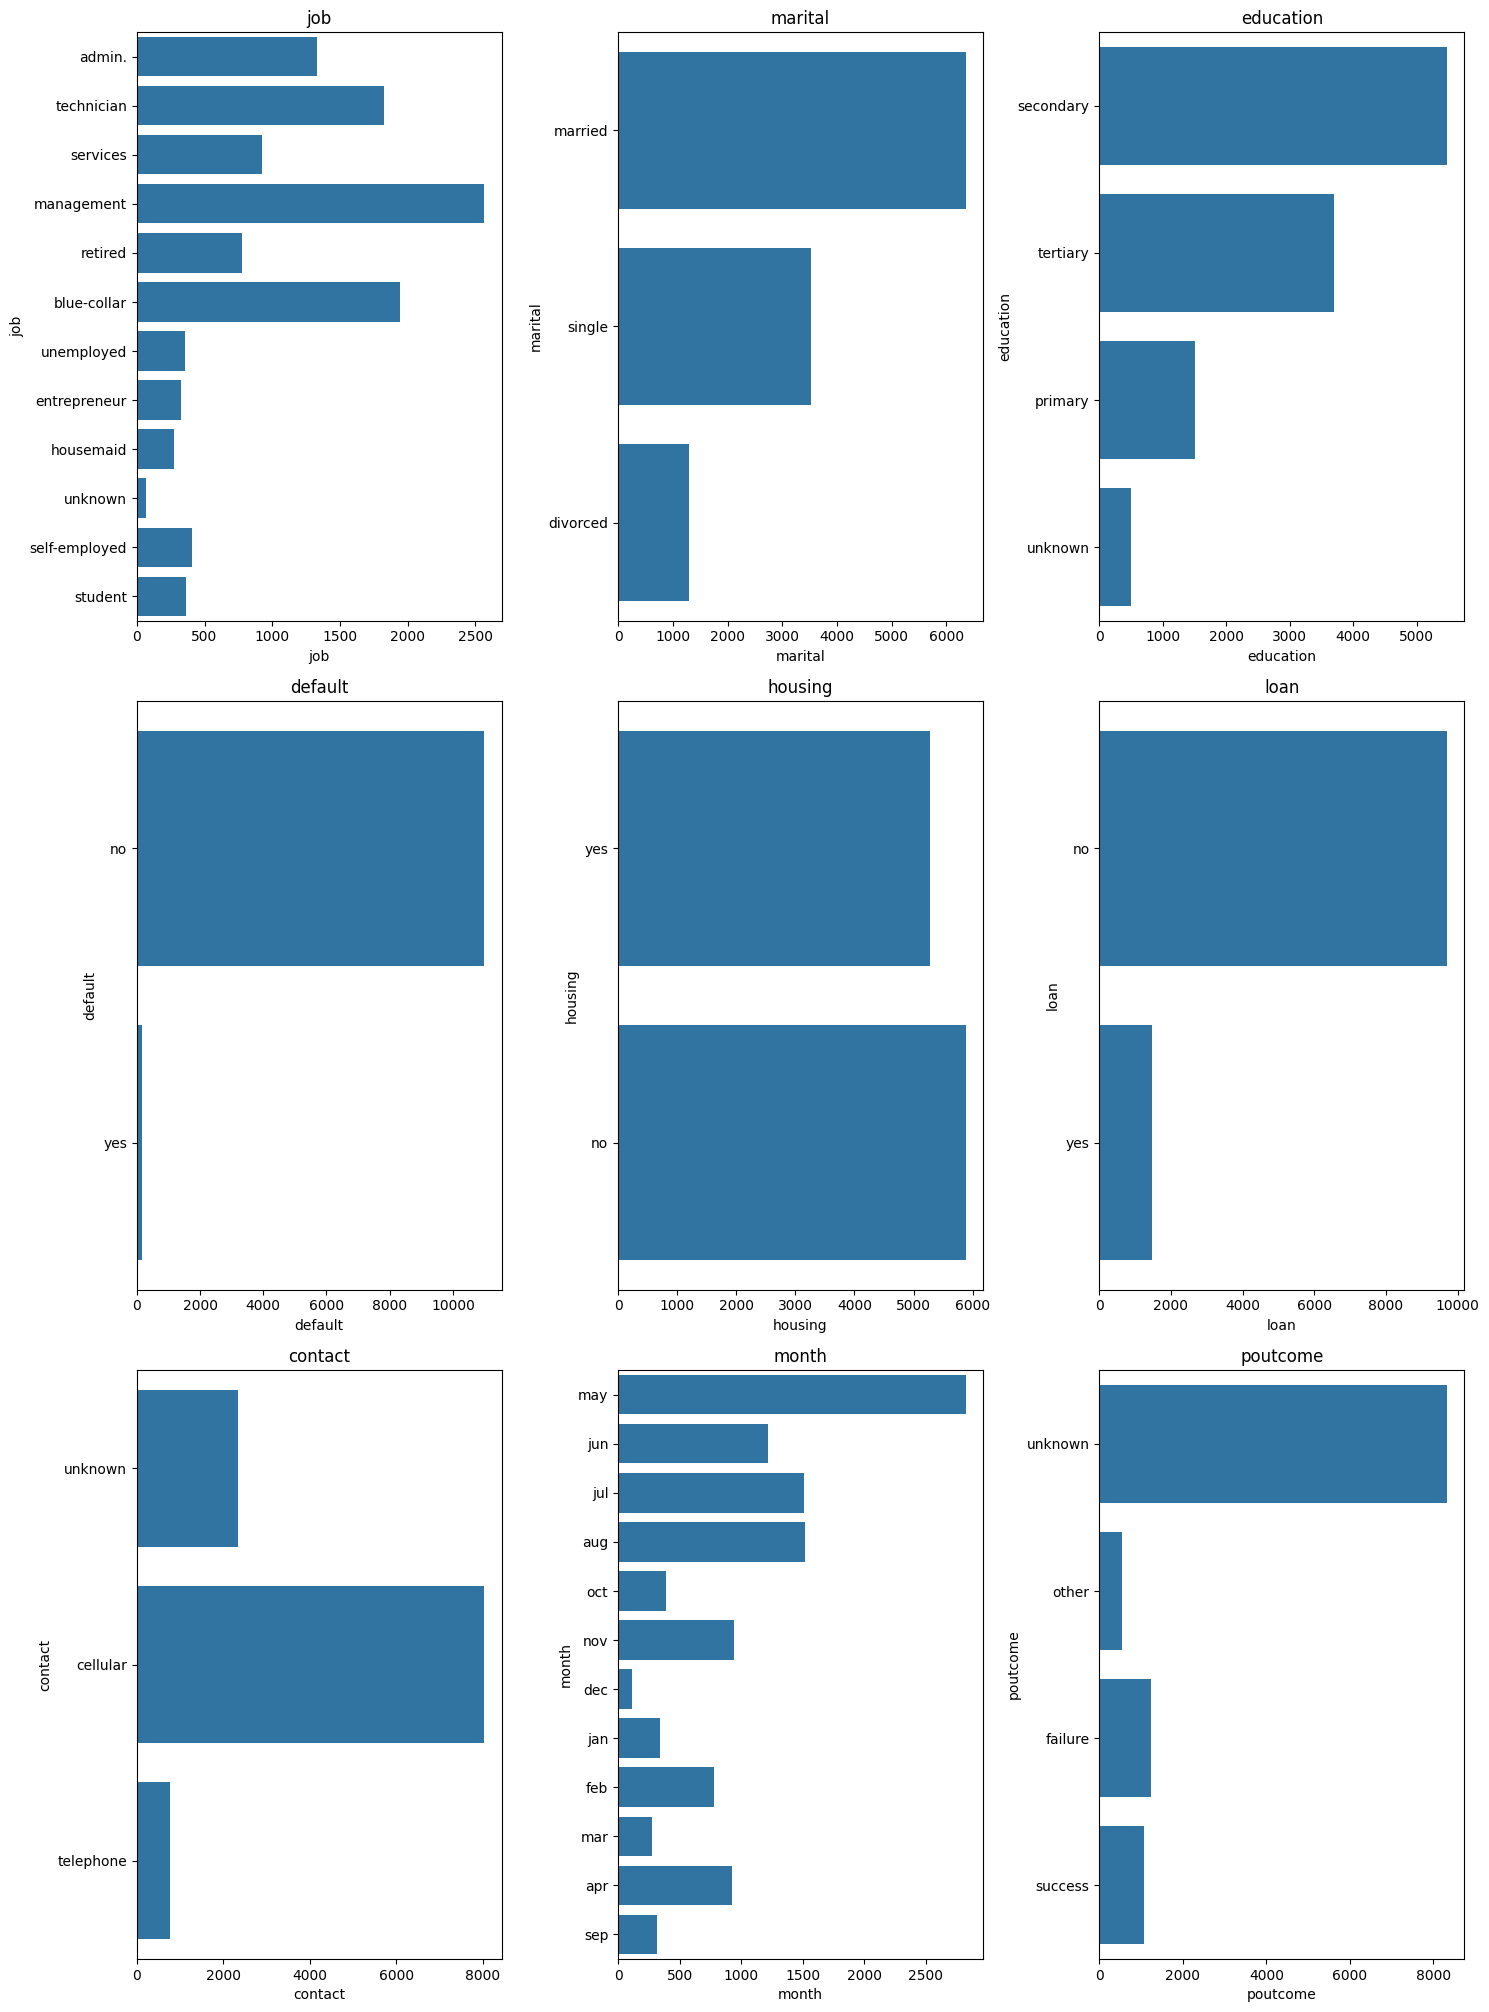

In [ ]:
plt.figure(figsize=(15, 80), facecolor='white')

for plotnumber, categorical_feature in enumerate(categorical_features, start=1):
    ax = plt.subplot(12, 3, plotnumber)
    sns.countplot(y=categorical_feature, data=df)
    ax.set_xlabel(categorical_feature)
    ax.set_title(categorical_feature)

plt.tight_layout()
plt.show()


Question 1a

In [ ]:
"Default feature is not useful as it has value of no at high ratio to value yes, thus it can be dropped"

'Default feature is not useful as it has value of no at high ratio to value yes, thus it can be dropped'

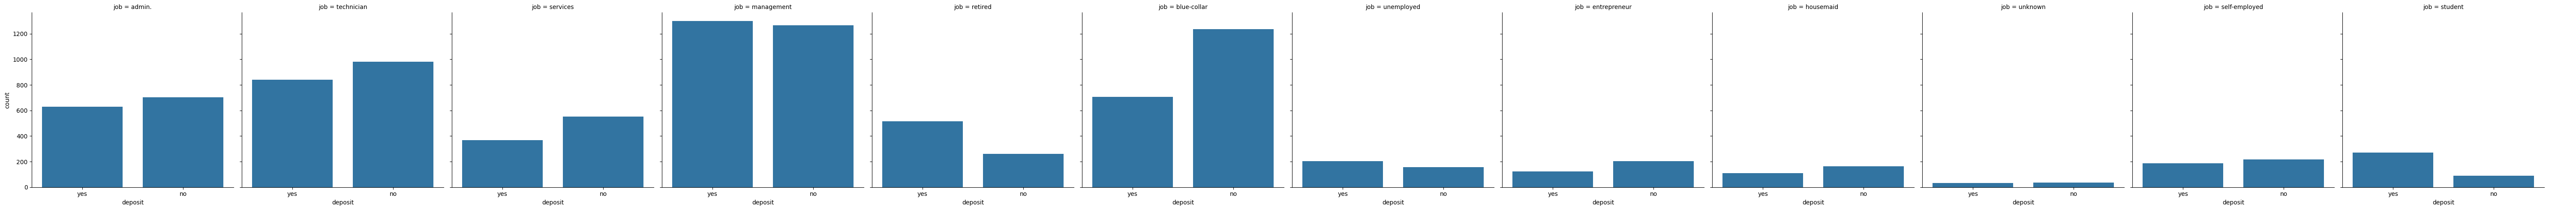

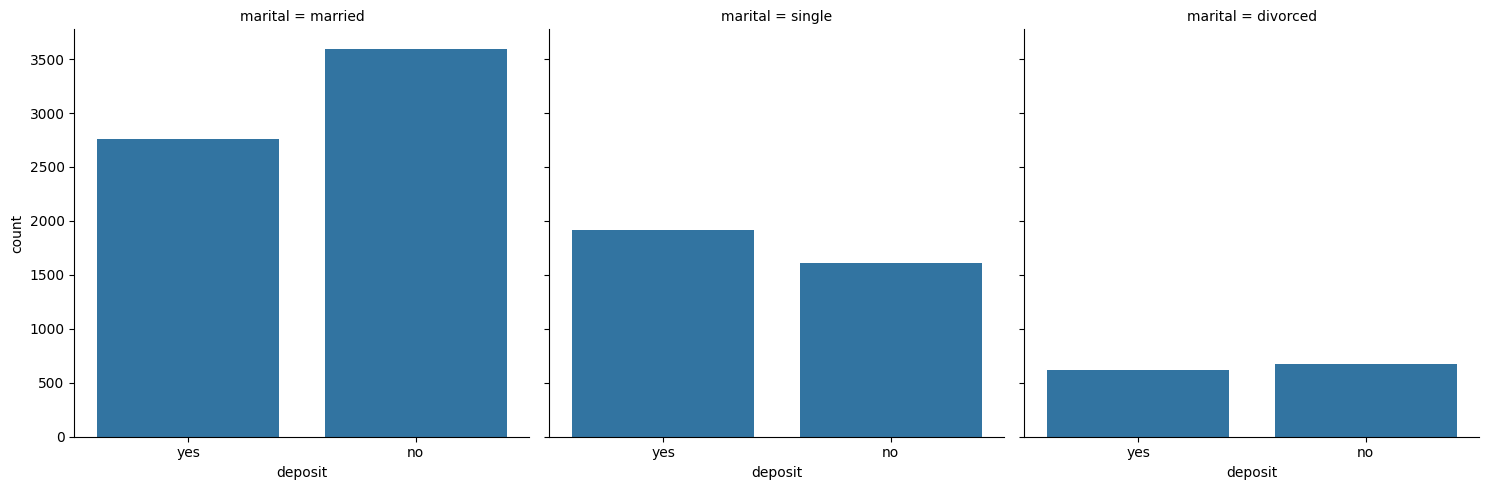

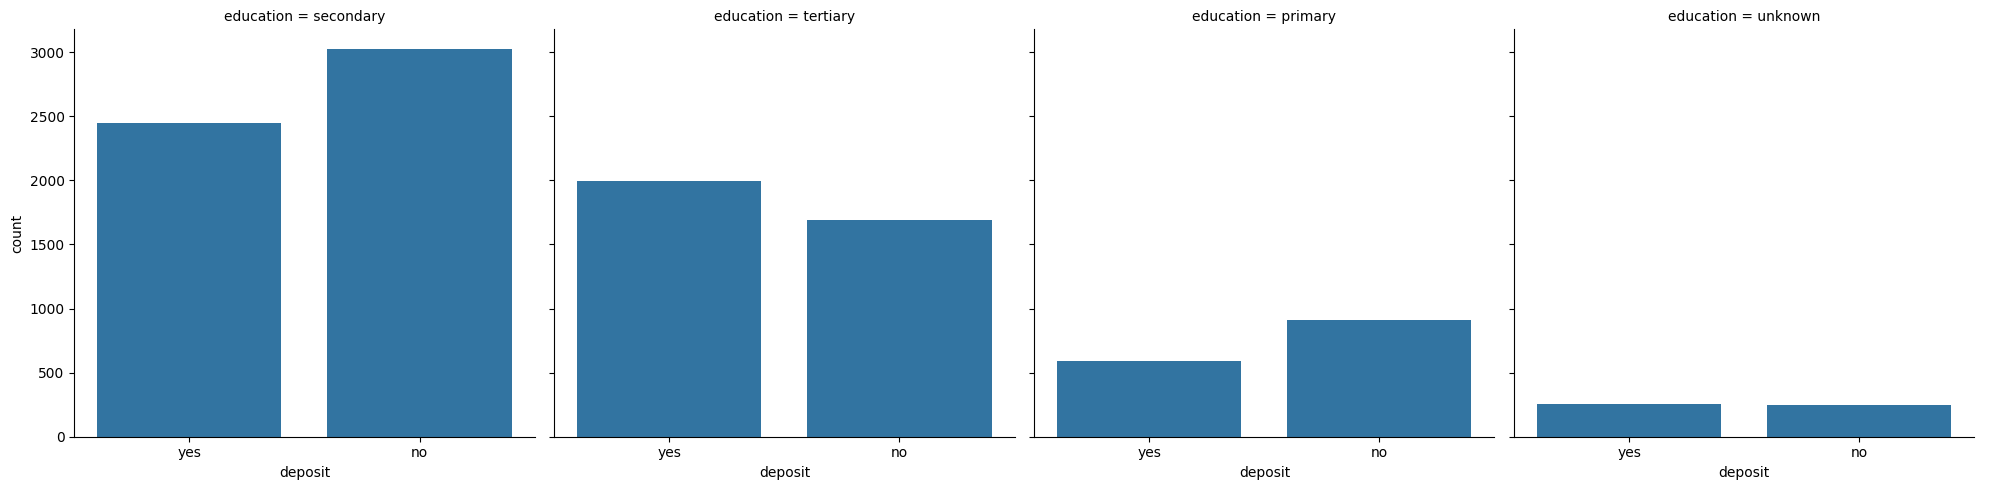

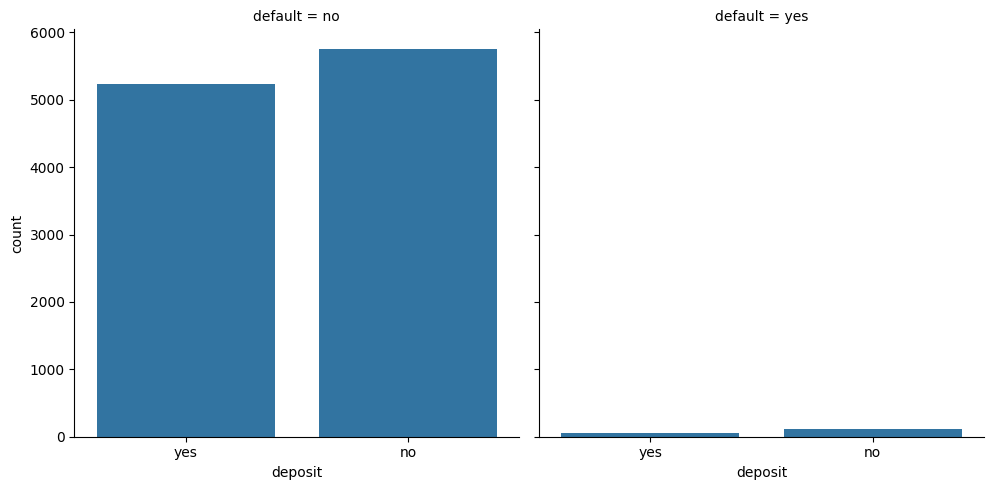

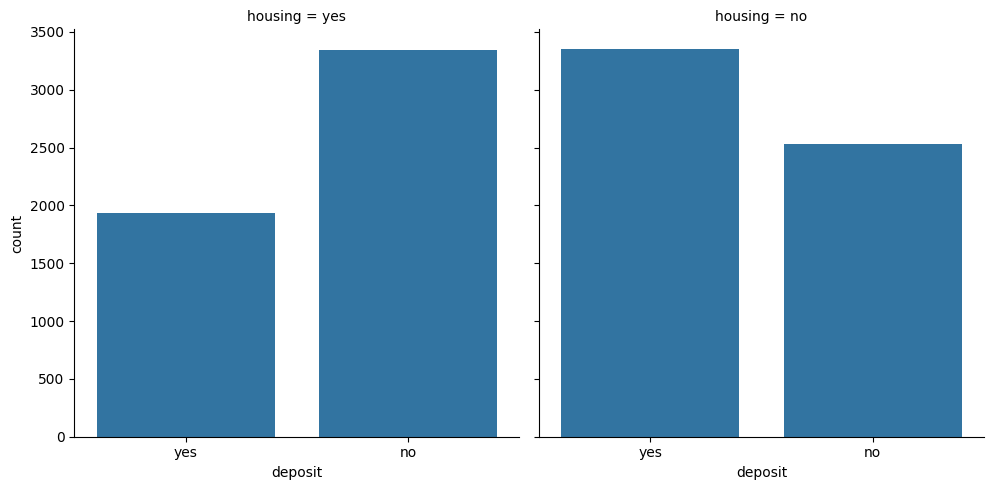

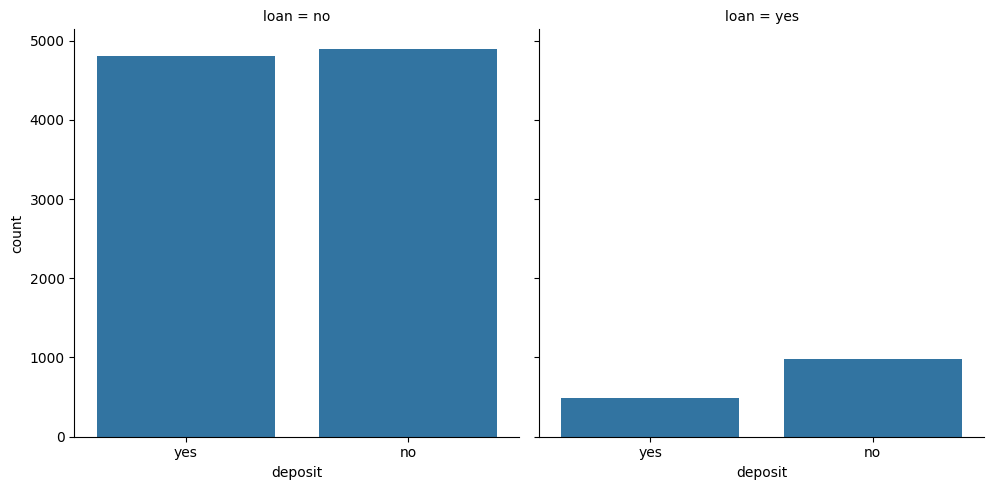

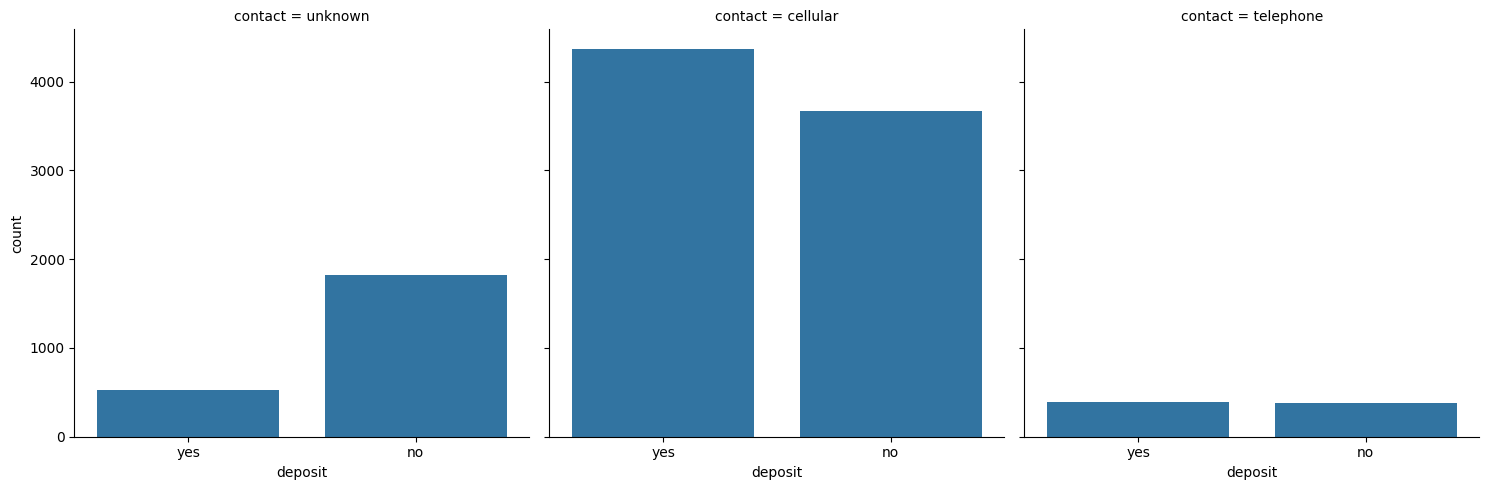

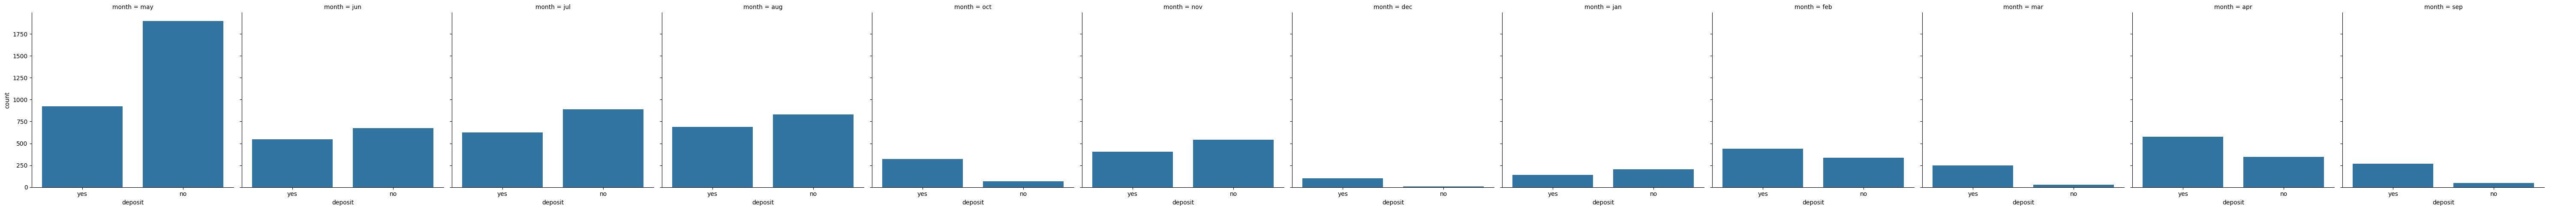

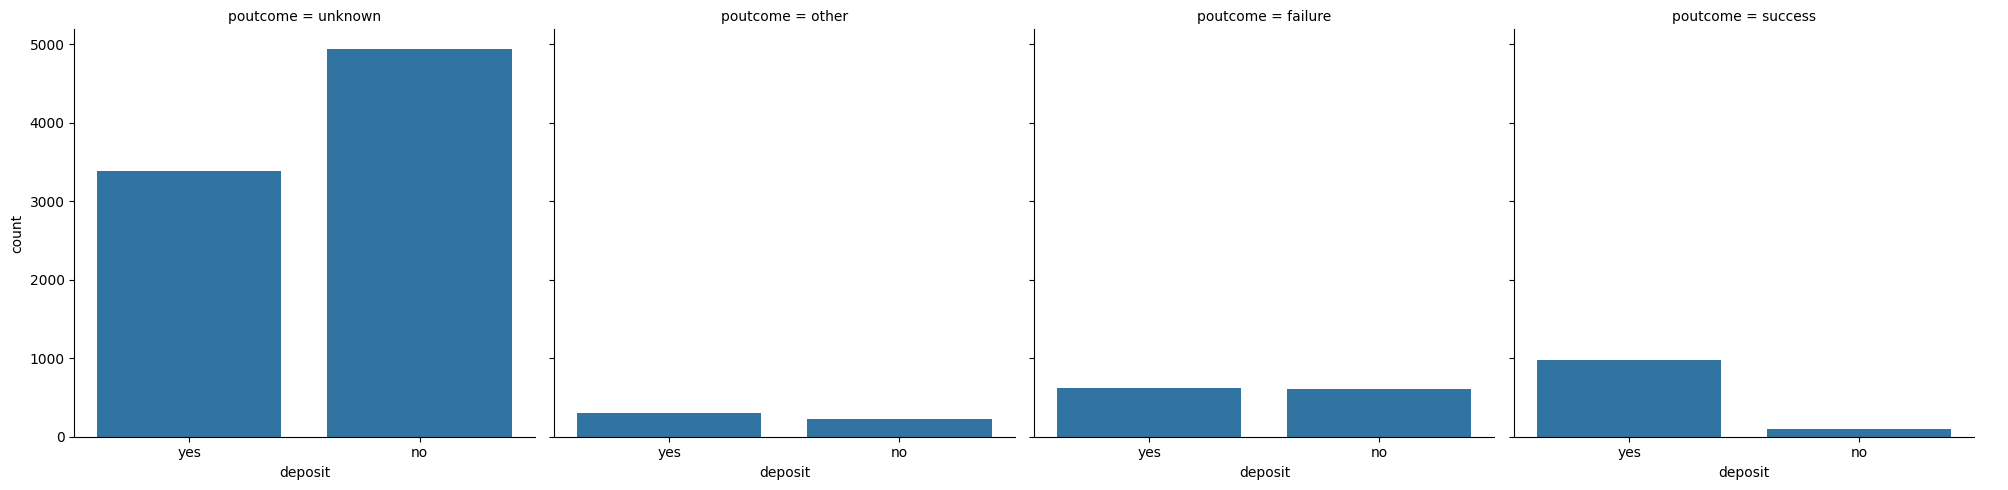

In [ ]:
for categorical_feature in categorical_features:
    sns.catplot(x='deposit', col=categorical_feature, kind='count', data= df)
plt.show()

In [ ]:
for categorical_feature in categorical_features:
    grouped_data = df.groupby(['deposit', categorical_feature]).size().reset_index(name='count')
    print(f"\nDistribution for: {categorical_feature}")
    display(grouped_data)



Distribution for: job


,deposit,job,count
0,no,admin.,703
1,no,blue-collar,1236
2,no,entrepreneur,205
3,no,housemaid,165
4,no,management,1265
5,no,retired,262
6,no,self-employed,218
7,no,services,554
8,no,student,91
9,no,technician,983



Distribution for: marital


,deposit,marital,count
0,no,divorced,671
1,no,married,3596
2,no,single,1606
3,yes,divorced,622
4,yes,married,2755
5,yes,single,1912



Distribution for: education


,deposit,education,count
0,no,primary,909
1,no,secondary,3026
2,no,tertiary,1693
3,no,unknown,245
4,yes,primary,591
5,yes,secondary,2450
6,yes,tertiary,1996
7,yes,unknown,252


... (8 outputs left out)


Distribution for: month


,deposit,month,count
0,no,apr,346
1,no,aug,831
2,no,dec,10
3,no,feb,335
4,no,jan,202
5,no,jul,887
6,no,jun,676
7,no,mar,28
8,no,may,1899
9,no,nov,540



Distribution for: poutcome


,deposit,poutcome,count
0,no,failure,610
1,no,other,230
2,no,success,93
3,no,unknown,4940
4,yes,failure,618
5,yes,other,307
6,yes,success,978
7,yes,unknown,3386


In [ ]:
numerical_features = [feature for feature in df.columns if ((df[feature].dtypes != 'O') & (feature not in ['deposit']))]
print('Number of numerical variables: ', len(numerical_features))

# visualise the numerical variables
df[numerical_features].head()

Number of numerical variables:  7


,age,balance,day,duration,campaign,pdays,previous
0,59,2343,5,1042,1,-1,0
1,56,45,5,1467,1,-1,0
2,41,1270,5,1389,1,-1,0
3,55,2476,5,579,1,-1,0
4,54,184,5,673,2,-1,0


Question 3b

In [ ]:
discrete_feature=[feature for feature in numerical_features if len(df[feature].unique())<25]
print("Discrete Variables Count: {}".format(len(discrete_feature)))

Discrete Variables Count: 0


In [ ]:
"There are no discrete variables"

'There are no discrete variables'

Question 3a

In [ ]:
continuous_features=[feature for feature in numerical_features if feature not in discrete_feature+['deposit']]
print("Continuous feature Count {}".format(len(continuous_features)))

Continuous feature Count 7


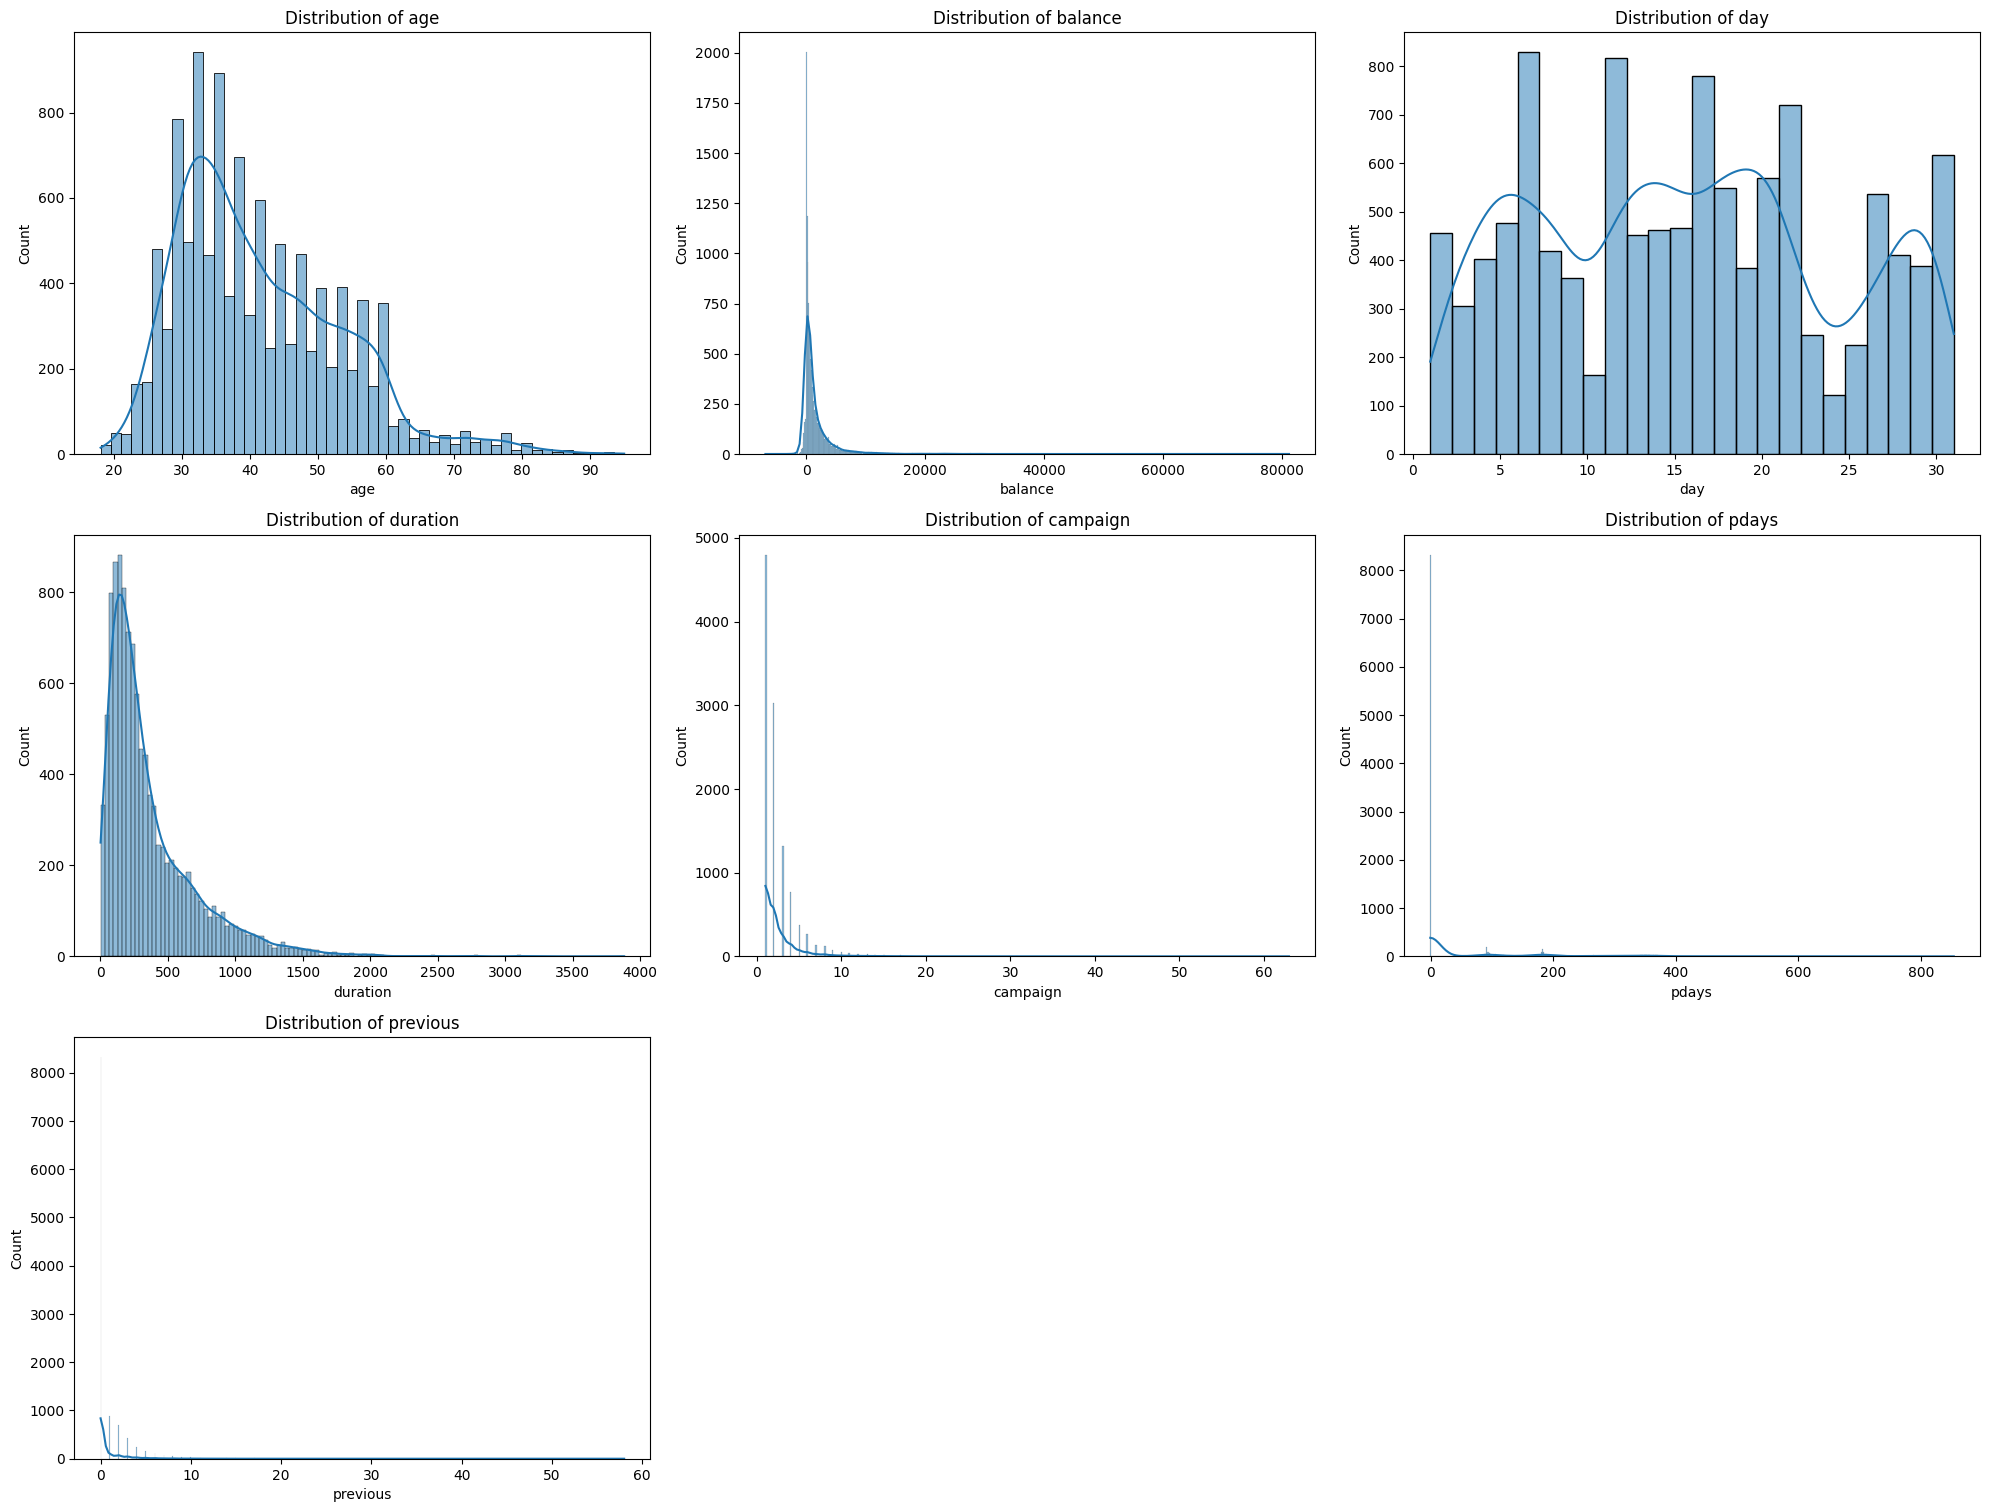

In [ ]:
plt.figure(figsize=(20, 60), facecolor='white')

for plotnumber, continuous_feature in enumerate(continuous_features, start=1):
    ax = plt.subplot(12, 3, plotnumber)
    sns.histplot(df[continuous_feature], kde=True, ax=ax)  `
    ax.set_xlabel(continuous_feature)
    ax.set_title(f'Distribution of {continuous_feature}')

plt.tight_layout()
plt.show()


In [ ]:
"""Age and Days columns are distributed normally, therefore they should be normalized,beacuse the performance of model drastically improves when the variables are normalized, rest which are skewed to the left should not be normalized"""

'Age and Days columns are distributed normally, therefore they should be normalized,beacuse the performance of model drastically improves when the variables are normalized, rest which are skewed to the left should not be normalized'

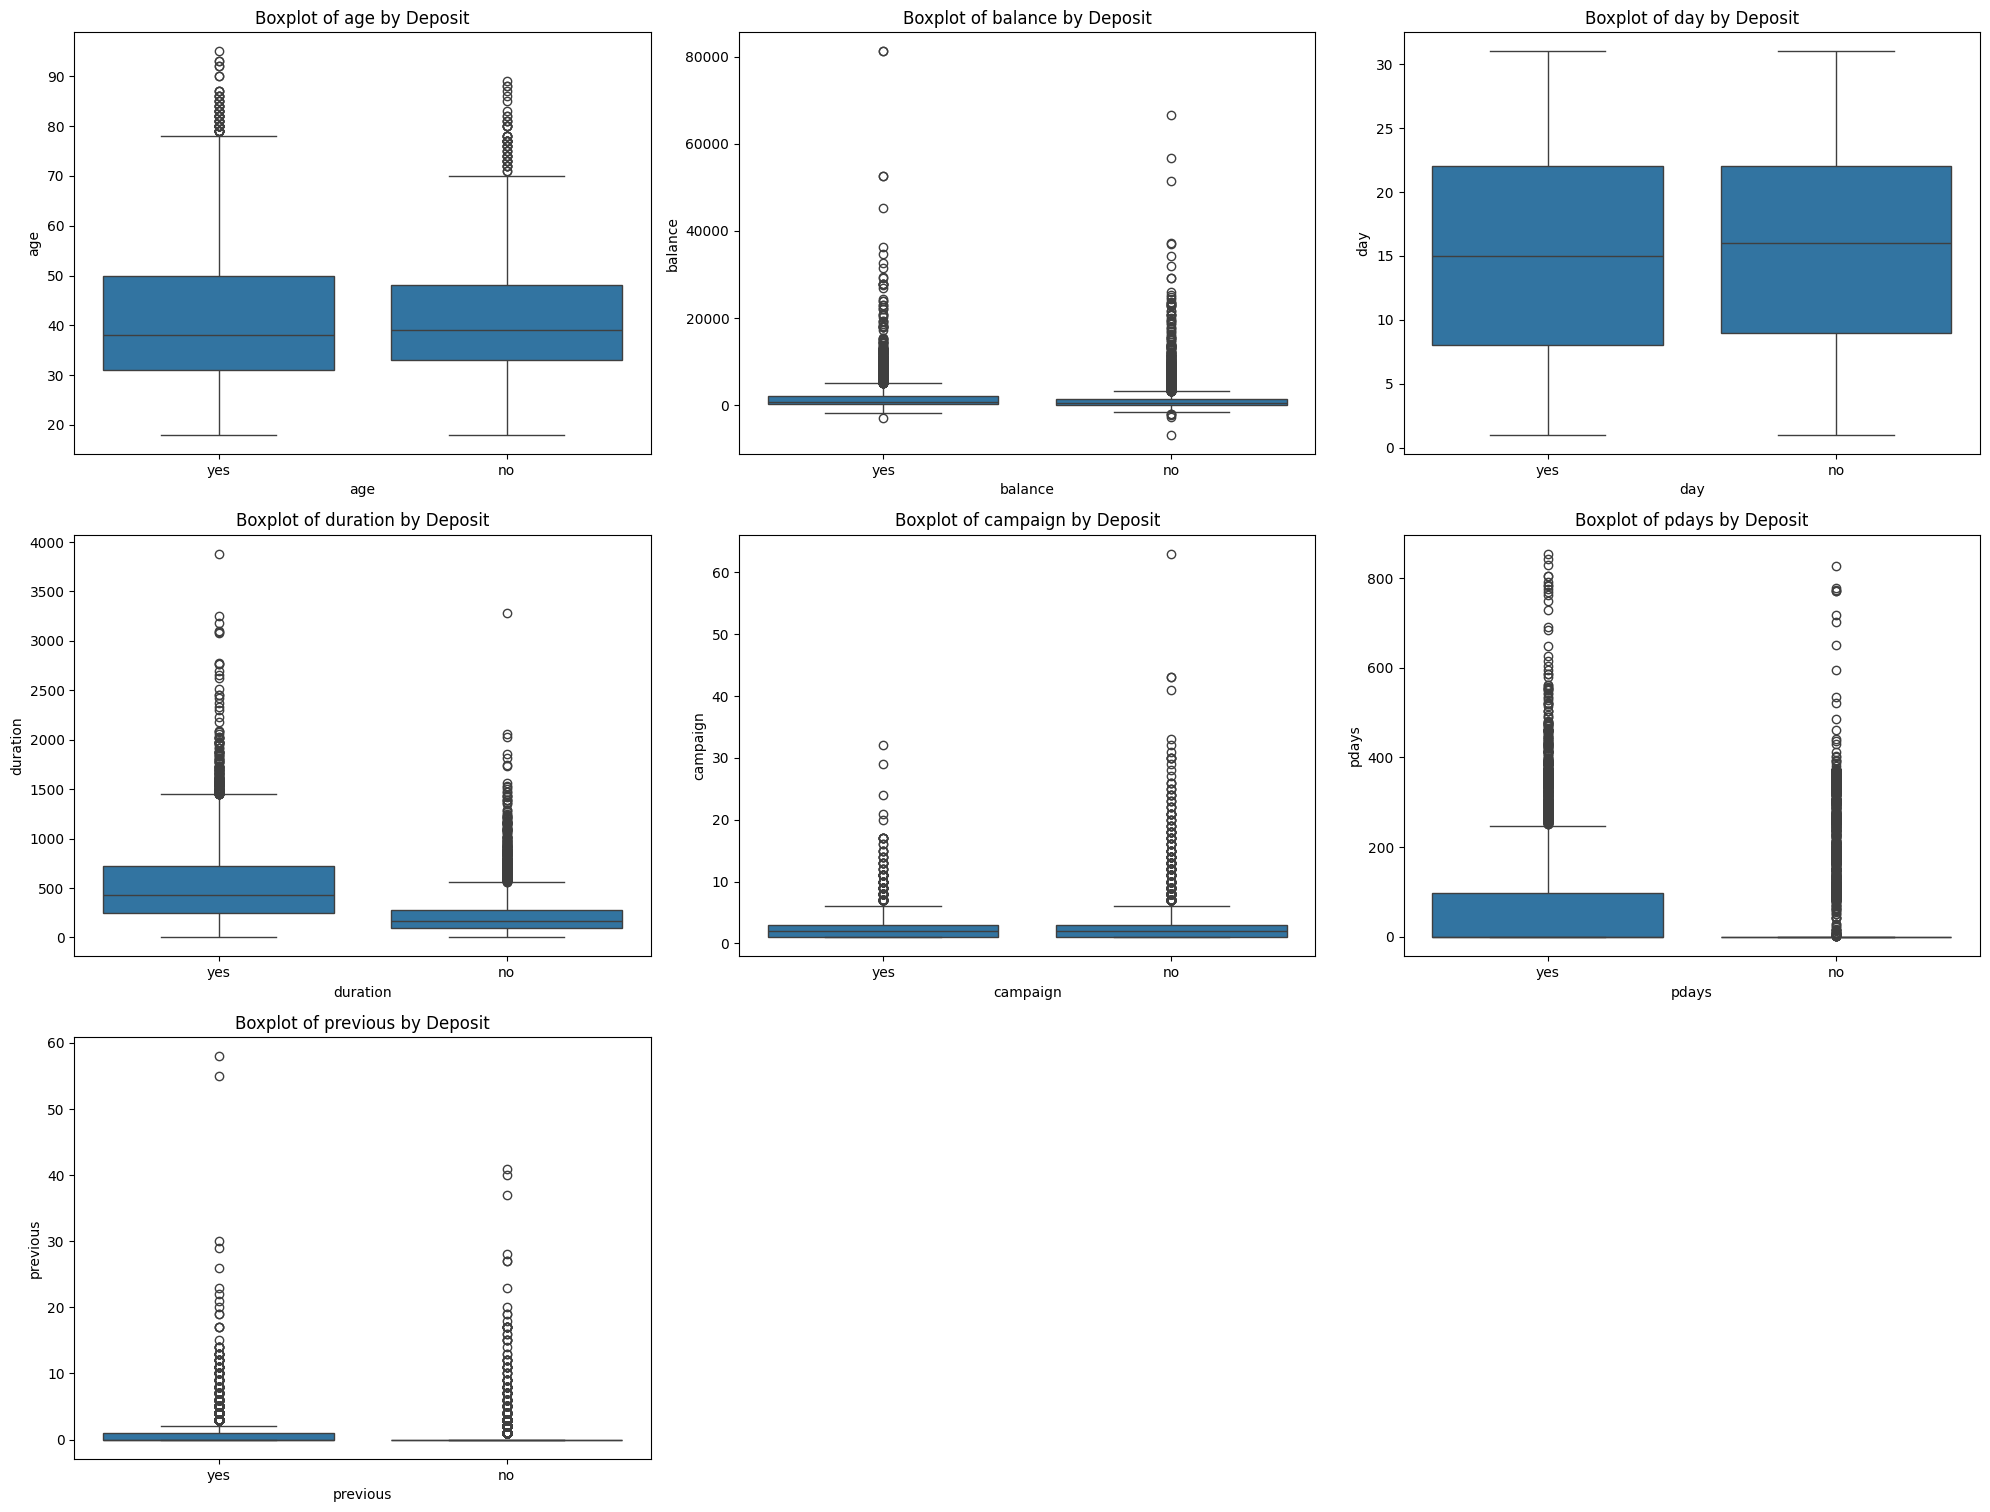

In [ ]:
plt.figure(figsize=(20, 60), facecolor='white')

for plotnumber, feature in enumerate(continuous_features, start=1):
    ax = plt.subplot(12, 3, plotnumber)
    sns.boxplot(x="deposit", y=feature, data=df, ax=ax)  # Pass `ax=ax` for better control
    ax.set_xlabel(feature)
    ax.set_title(f'Boxplot of {feature} by Deposit')

plt.tight_layout()
plt.show()


Question 3c

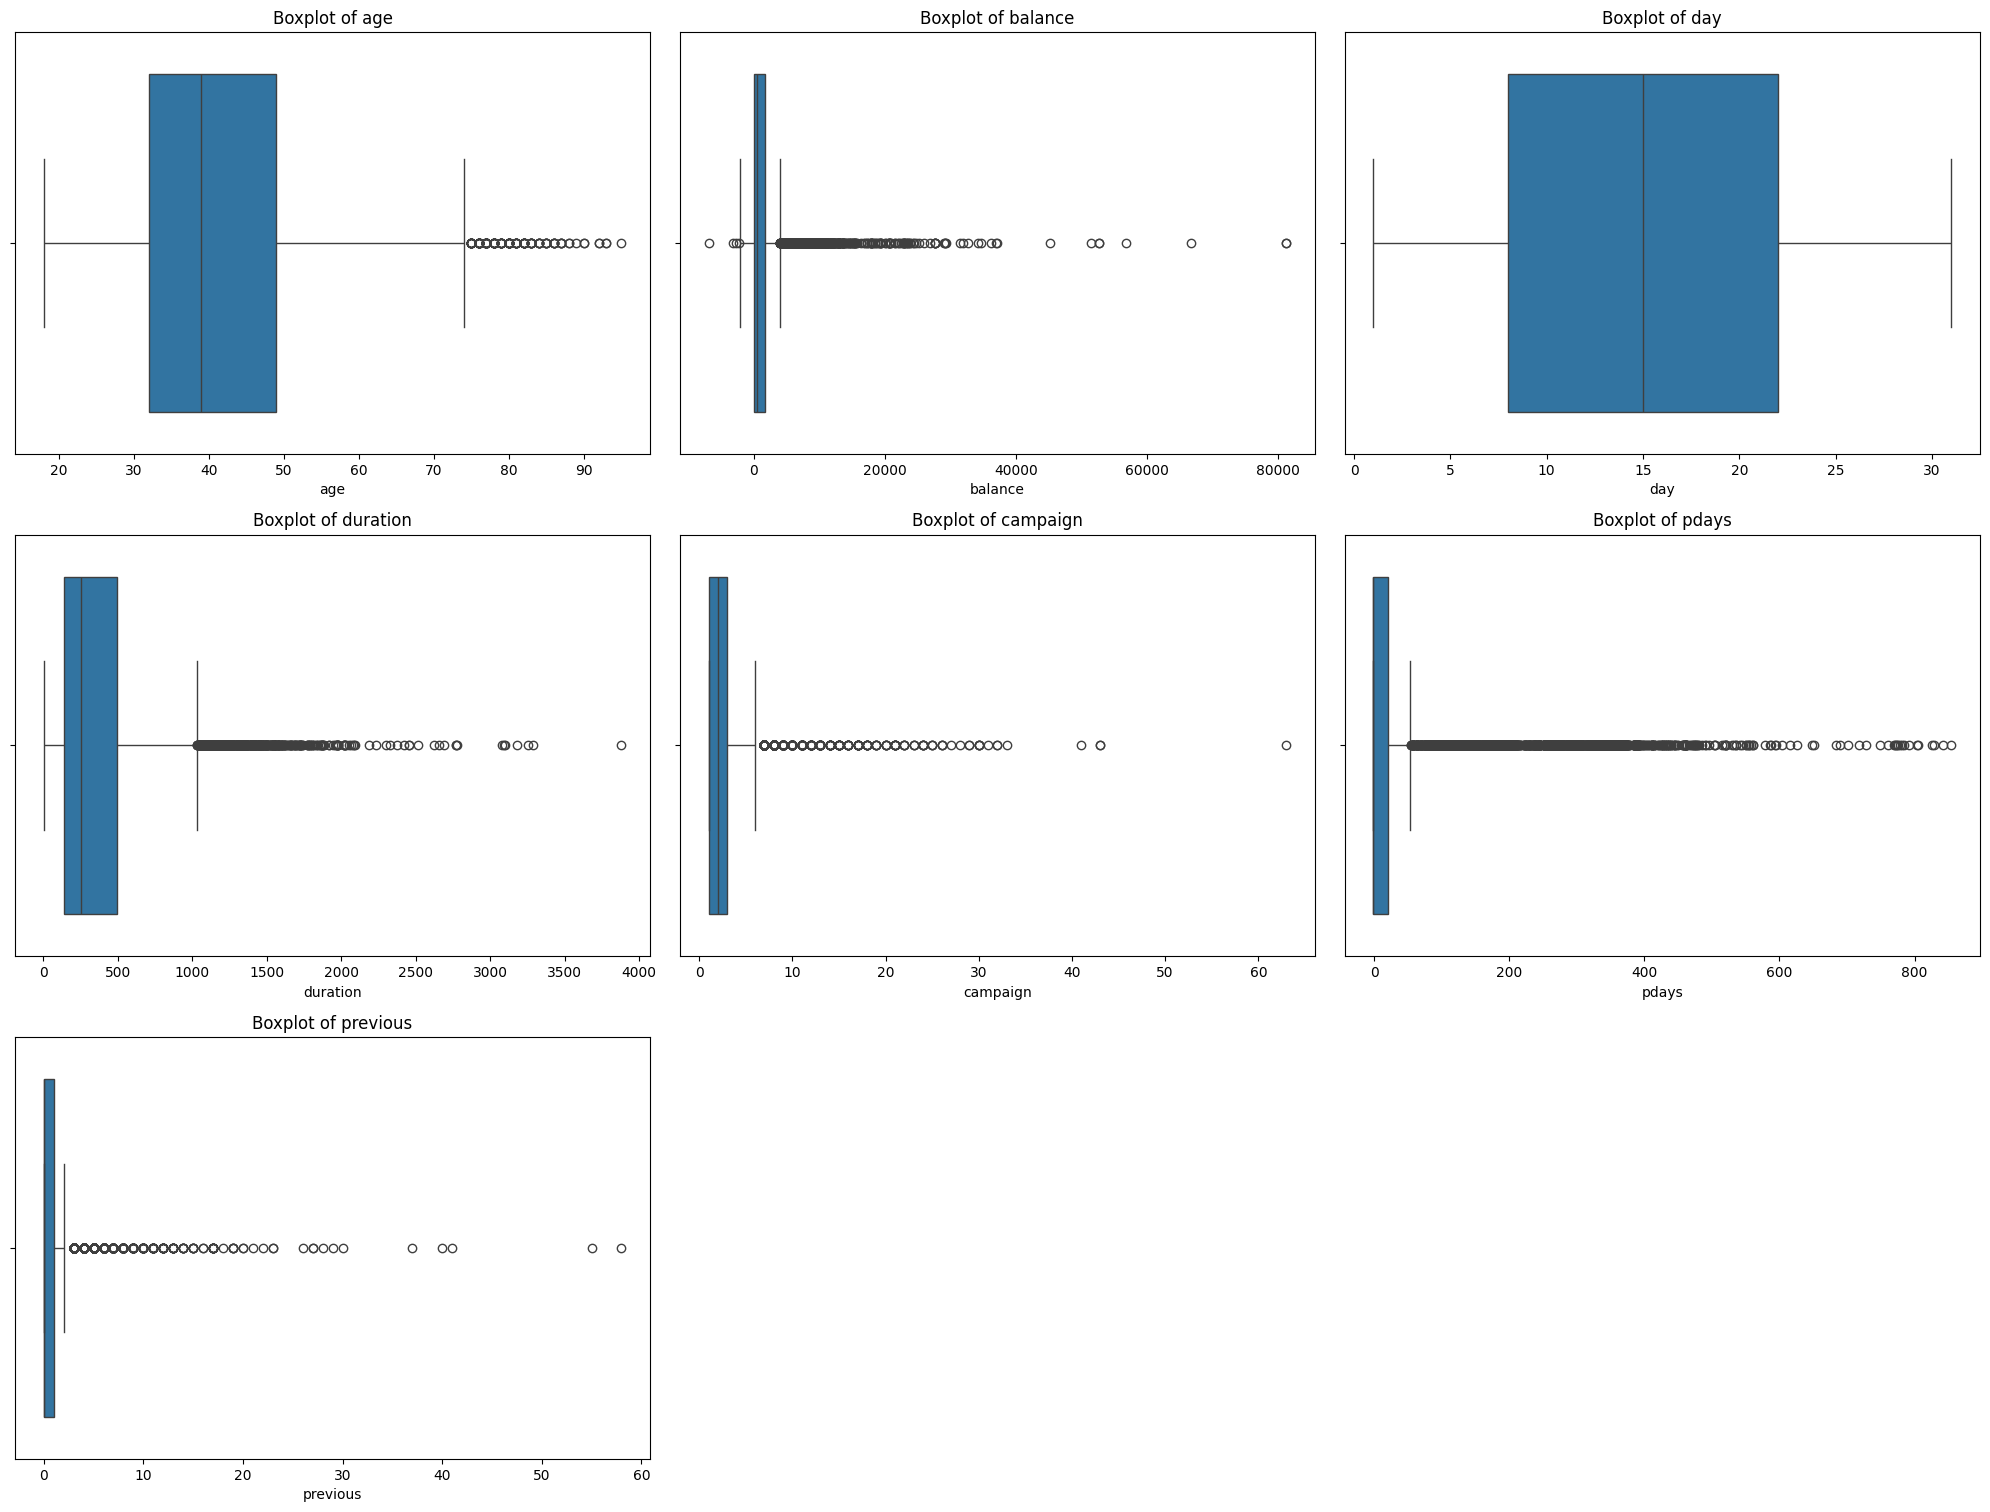

In [ ]:
plt.figure(figsize=(20, 60), facecolor='white')

for plotnumber, numerical_feature in enumerate(numerical_features, start=1):
    ax = plt.subplot(12, 3, plotnumber)
    sns.boxplot(x=df[numerical_feature], ax=ax)
    ax.set_xlabel(numerical_feature)
    ax.set_title(f'Boxplot of {numerical_feature}')

plt.tight_layout()
plt.show()


In [ ]:
"age, balance, duration, compaign, pdays and previous has some outliers"


'age, balance, duration, compaign, pdays and previous has some outliers'

Question 1b

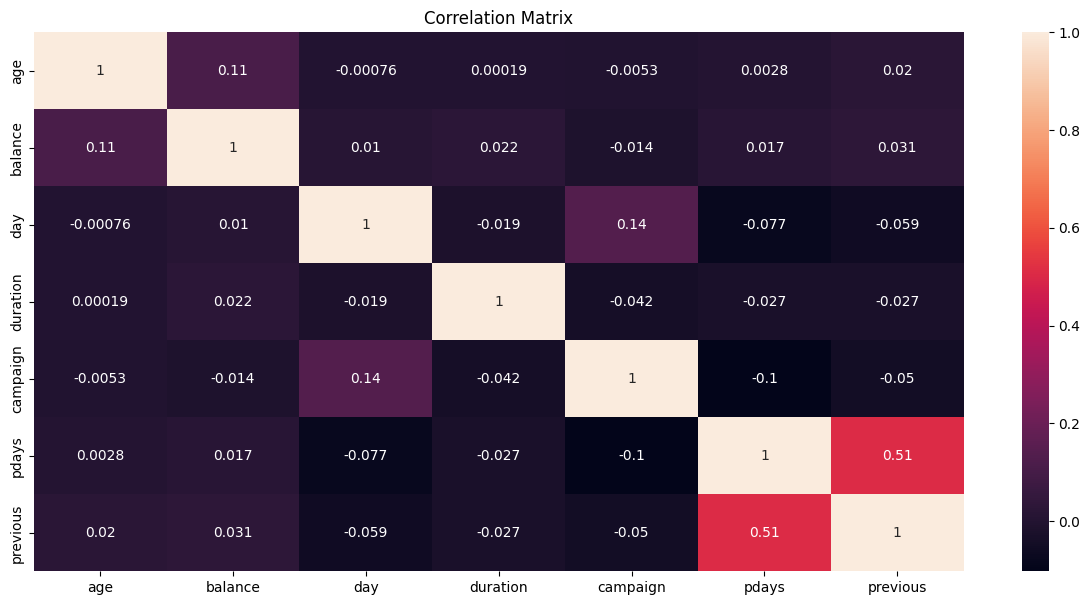

In [ ]:
cor_mat = df.select_dtypes(include=[np.number]).corr()

fig = plt.figure(figsize=(15, 7))
sns.heatmap(cor_mat, annot=True)

plt.title("Correlation Matrix")
plt.show()


There is no feature heavily correlated with other features except previous and pdays

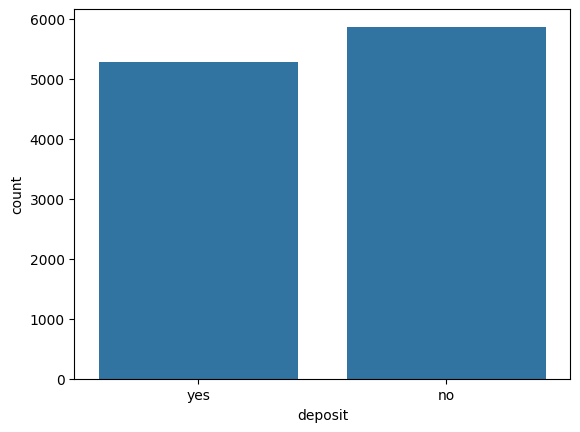

In [ ]:
sns.countplot(x='deposit',data=df)
plt.show()

Question 2

In [ ]:
#Since the target variable is nearly balanced, we should use metric Accuracy and F1 score since they provide better results when the target variable is balanced

Question 1c

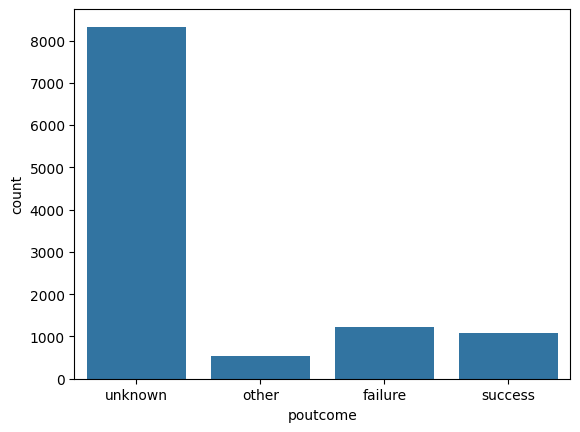

In [ ]:
sns.countplot(x='poutcome',data=df)
plt.show()

In [ ]:
"The classes are imbalanced, with the majority of samples belonging to the 'unknown' class."

"The classes are imbalanced, with the majority of samples belonging to the 'unknown' class."

Question 1d

In [ ]:
"Since the poutcome column represents the outcome of the previous marketing campaign,I'll only use samples with a known outcome, which are success, failure and other"

"Since the poutcome column represents the outcome of the previous marketing campaign,I'll only use samples with a known outcome, which are success, failure and other"

In [ ]:
df['deposit'].groupby(df['deposit']).count()


,deposit
deposit,
no,5873
yes,5289


In [ ]:
df2=df.copy()


In [ ]:
df2.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [ ]:
df2.shape

(11162, 17)

In [ ]:
#default features does not play imp role
df2.groupby(['deposit','default']).size()

deposit  default
no       no         5757
         yes         116
yes      no         5237
         yes          52
dtype: int64

In [ ]:
df2.drop(['default'],axis=1, inplace=True)


In [ ]:
df2.groupby(['deposit','pdays']).size()


deposit  pdays
no       -1       4940
          1          2
          2          6
          5          2
          6          2
                  ... 
yes       804        1
          805        1
          828        1
          842        1
          854        1
Length: 732, dtype: int64

In [ ]:
# dropping pdays as it has -1 value for around 40%+
df2.drop(['pdays'],axis=1, inplace=True)


Removing Outliers

In [ ]:
df2.groupby('age',sort=True)['age'].count()


,age
age,
18,8
19,13
20,20
21,30
22,48
...,...
89,1
90,2
92,2


In [ ]:
df2.groupby(['deposit','balance'],sort=True)['balance'].count()


deposit  balance
no       -6847      1
         -2712      1
         -2282      1
         -2049      1
         -1965      1
                   ..
yes       34646     1
          36252     1
          45248     1
          52587     2
          81204     2
Name: balance, Length: 5082, dtype: int64

In [ ]:
df2.groupby(['deposit','duration'],sort=True)['duration'].count()


deposit  duration
no       2           1
         3           1
         4           2
         5           4
         6           6
                    ..
yes      3094        1
         3102        1
         3183        1
         3253        1
         3881        1
Name: duration, Length: 2157, dtype: int64

In [ ]:
df2.groupby(['deposit','campaign'],sort=True)['campaign'].count()


deposit  campaign
no       1           2237
         2           1627
         3            703
         4            454
         5            239
         6            173
         7             92
         8             96
         9             51
         10            38
         11            24
         12            25
         13            24
         14            11
         15             9
         16             7
         17             8
         18             8
         19             5
         20             4
         21             7
         22             4
         23             3
         24             4
         25             3
         26             3
         27             1
         28             1
         29             1
         30             4
         31             1
         32             1
         33             1
         41             1
         43             2
         63             1
yes      1           2561
         2           1401
         3            618
         4            317
         5            139
         6             92
         7             47
         8             32
         9             21
         10            14
         11            16
         12             4
         13             6
         14             4
         15             4
         16             2
         17             6
         20             1
         21             1
         24             1
         29             1
         32             1
Name: campaign, dtype: int64

In [ ]:
df3 = df2[df2['campaign'] < 33]
df3.groupby(['deposit','campaign'],sort=True)['campaign'].count()


deposit  campaign
no       1           2237
         2           1627
         3            703
         4            454
         5            239
         6            173
         7             92
         8             96
         9             51
         10            38
         11            24
         12            25
         13            24
         14            11
         15             9
         16             7
         17             8
         18             8
         19             5
         20             4
         21             7
         22             4
         23             3
         24             4
         25             3
         26             3
         27             1
         28             1
         29             1
         30             4
         31             1
         32             1
yes      1           2561
         2           1401
         3            618
         4            317
         5            139
         6             92
         7             47
         8             32
         9             21
         10            14
         11            16
         12             4
         13             6
         14             4
         15             4
         16             2
         17             6
         20             1
         21             1
         24             1
         29             1
         32             1
Name: campaign, dtype: int64

In [ ]:
df3.groupby(['deposit','previous'],sort=True)['previous'].count()


deposit  previous
no       0           4935
         1            304
         2            237
         3            141
         4             73
         5             44
         6             34
         7             23
         8             21
         9             10
         10             4
         11             8
         12             6
         13             2
         14             1
         15             4
         16             2
         17             8
         18             1
         19             2
         20             1
         23             1
         27             2
         28             1
         37             1
         40             1
         41             1
yes      0           3384
         1            583
         2            456
         3            294
         4            171
         5            121
         6             83
         7             54
         8             39
         9             24
         10            26
         11            15
         12            10
         13             9
         14             5
         15             1
         17             3
         19             2
         20             1
         21             1
         22             1
         23             1
         26             1
         29             1
         30             1
         55             1
         58             1
Name: previous, dtype: int64

In [ ]:
df4 = df3[df3['previous'] < 31]


In [ ]:
df4 = df3[df3['poutcome'] != 'unknown']

**One Hot Encoding**

In [ ]:
cat_columns = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
for col in  cat_columns:
    df4 = pd.concat([df4.drop(col, axis=1),pd.get_dummies(df4[col], prefix=col, prefix_sep='_',drop_first=True, dummy_na=False)], axis=1)

In [ ]:
bool_columns = ['housing', 'loan', 'deposit']
for col in  bool_columns:
    df4[col+'_new']=df4[col].apply(lambda x : 1 if x == 'yes' else 0)
    df4.drop(col, axis=1, inplace=True)

In [ ]:
df4.head()


,age,balance,day,duration,campaign,previous,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,housing_new,loan_new,deposit_new
890,42,-247,21,519,1,1,False,False,False,False,...,False,False,False,True,False,True,False,1,1,1
891,33,3444,21,144,1,4,False,False,False,False,...,False,False,False,True,False,False,False,1,0,1
899,56,589,23,518,1,2,False,False,False,False,...,False,False,False,True,False,False,True,1,0,1
933,34,899,12,114,1,3,False,False,False,False,...,False,False,True,False,False,False,False,1,0,1
951,53,2269,17,1091,2,1,False,False,False,False,...,False,False,True,False,False,False,True,0,0,1


Question 4
Splitting the dataset into Train and Test

In [166]:
from sklearn.model_selection import train_test_split

test_fraction = 0.2
train_df4, test_df4 = train_test_split(df4, test_size=test_fraction, stratify=df4['deposit_new'], random_state=42)

print("Train set deposit distribution:")
print(train_df4['deposit_new'].value_counts(normalize=True).to_markdown(numalign="left", stralign="left"))
print("\nTest set deposit distribution:")
print(test_df4['deposit_new'].value_counts(normalize=True).to_markdown(numalign="left", stralign="left"))

#[1] https://g.co/gemini/share/559ae2cf108e
# I took help from gemini then found out the proportion of distribution in Train and Test set using value_counts

Train set deposit distribution:
| deposit_new   | proportion   |
|:--------------|:-------------|
| 1             | 0.671076     |
| 0             | 0.328924     |

Test set deposit distribution:
| deposit_new   | proportion   |
|:--------------|:-------------|
| 1             | 0.670775     |
| 0             | 0.329225     |


Question 5
Five fold cross validation and Grid Search CV

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

# Defining the parameter grids for each model
param_grid_svm = {
    'C': [0.1, 1, 10],
    'gamma': [0.1, 1, 10]
}

param_grid_nn = {
    'hidden_layer_sizes': [(10,), (50,), (100,)],
    'alpha': [0.0001, 0.001, 0.01]
}

param_grid_rf = {
    'max_depth': [5, 10, 20],
    'max_features': ['sqrt', 'log2']
}

# Creating the models
svm = SVC(kernel='rbf')
nn = MLPClassifier(activation='relu', solver='adam', random_state=42)
rf = RandomForestClassifier(random_state=42)

# Creating the GridSearchCV objects for each model
grid_svm = GridSearchCV(svm, param_grid_svm, cv=5)
grid_nn = GridSearchCV(nn, param_grid_nn, cv=5)
grid_rf = GridSearchCV(rf, param_grid_rf, cv=5)

X_train = train_df4.drop('deposit_new', axis=1)
y_train = train_df4['deposit_new']

grid_svm.fit(X_train, y_train)
grid_nn.fit(X_train, y_train)
grid_rf.fit(X_train, y_train)

print("Best hyperparameters for SVM:", grid_svm.best_params_)
print("Best hyperparameters for Neural Network:", grid_nn.best_params_)
print("Best hyperparameters for Random Forest:", grid_rf.best_params_)

#[2] https://youtu.be/gJo0uNL-5Qw?si=7u20UFt97Cs-w5nw
#[3]https://youtu.be/HdlDYng8g9s?si=4WftNXMGEYdBmogL
#[4]https://youtu.be/5Xh9FusE8iE?si=mwTV0JhYj3v65Bmh
#I refered to the Youtube videos above to learn about K-Fold cross validation and GridSearchCV

Best hyperparameters for SVM: {'C': 0.1, 'gamma': 0.1}
Best hyperparameters for Neural Network: {'alpha': 0.0001, 'hidden_layer_sizes': (50,)}
Best hyperparameters for Random Forest: {'max_depth': 10, 'max_features': 'sqrt'}


Question 6 - Feature importance for each model

<Figure size 1000x600 with 0 Axes>

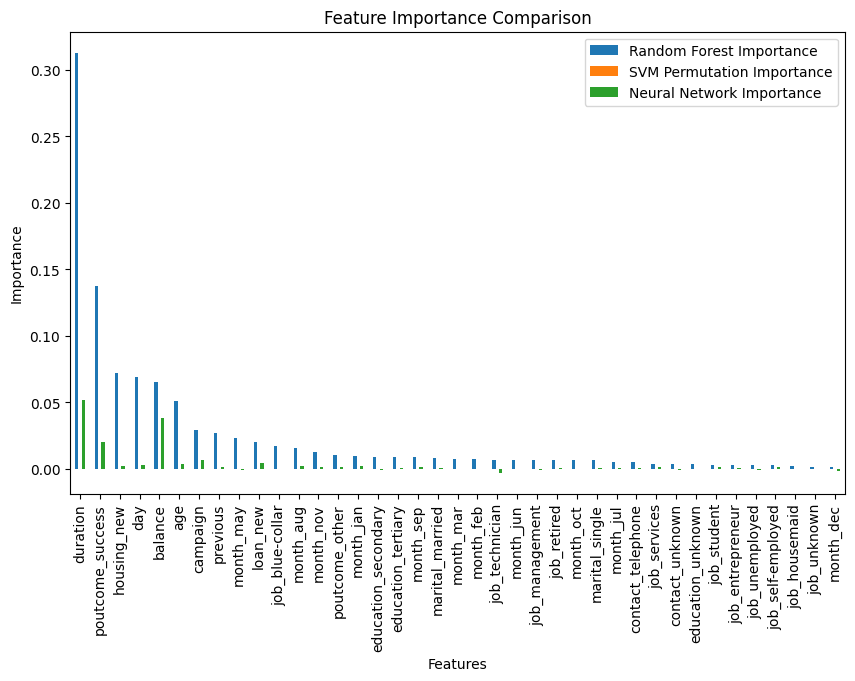

                Feature  Random Forest Importance  SVM Permutation Importance  \
3              duration                  0.312969                         0.0   
36     poutcome_success                  0.137521                         0.0   
37          housing_new                  0.071979                         0.0   
2                   day                  0.068766                         0.0   
1               balance                  0.065258                         0.0   
0                   age                  0.050800                         0.0   
4              campaign                  0.029061                         0.0   
5              previous                  0.026925                         0.0   
31            month_may                  0.023017                         0.0   
38             loan_new                  0.020404                         0.0   
6       job_blue-collar                  0.017067                         0.0   
24            month_aug     

In [ ]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

rf_best_model = grid_rf.best_estimator_
rf_feature_importance = rf_best_model.feature_importances_

svm_best_model = grid_svm.best_estimator_
svm_perm_importance = permutation_importance(svm_best_model, X_train, y_train, n_repeats=2, random_state=42, n_jobs=-1)  # Use parallel processing

nn_best_model = grid_nn.best_estimator_
nn_perm_importance = permutation_importance(nn_best_model, X_train, y_train, n_repeats=2, random_state=42, n_jobs=-1)  # Use parallel processing

features = X_train.columns
importance_df = pd.DataFrame({
    'Feature': features,
    'Random Forest Importance': rf_feature_importance,
    'SVM Permutation Importance': svm_perm_importance.importances_mean,
    'Neural Network Importance': nn_perm_importance.importances_mean
})

importance_df = importance_df.sort_values(by='Random Forest Importance', ascending=False)

plt.figure(figsize=(10, 6))
importance_df.set_index('Feature').plot(kind='bar', figsize=(10, 6))
plt.title("Feature Importance Comparison")
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()

print(importance_df)

#[5]https://chatgpt.com/share/6734e535-b374-8009-bfcc-4ee713d66401
#[6] Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. Decision Support Systems, 62, 22–31. https://doi.org/10.1016/j.dss.2014.03.001
#I modified n-repeats to reduce the computational costs so that code executes fast


In [ ]:
# The bar chart showcases that each feature has different importance for each model

Question 8 - Testing models on test data

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

X = df4.drop('deposit_new', axis=1)
y = df4['deposit_new']

svm = SVC(C=10, gamma=0.1)
nn = MLPClassifier(alpha=0.001, hidden_layer_sizes=(10,))
rf = RandomForestClassifier(max_depth=20, max_features='log2')

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

svm_scores = []
nn_scores = []
rf_scores = []

for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
    print(f"Fold {fold + 1}")
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    svm.fit(X_train, y_train)
    y_pred_svm = svm.predict(X_test)
    accuracy_svm = accuracy_score(y_test, y_pred_svm)
    svm_scores.append(accuracy_svm)
    print(f"  SVM Accuracy: {accuracy_svm}")

    nn.fit(X_train, y_train)
    y_pred_nn = nn.predict(X_test)
    accuracy_nn = accuracy_score(y_test, y_pred_nn)
    nn_scores.append(accuracy_nn)
    print(f"  Neural Network Accuracy: {accuracy_nn}")

    rf.fit(X_train, y_train)
    y_pred_rf = rf.predict(X_test)
    accuracy_rf = accuracy_score(y_test, y_pred_rf)
    rf_scores.append(accuracy_rf)
    print(f"  Random Forest Accuracy: {accuracy_rf}")

avg_accuracy_svm = sum(svm_scores) / len(svm_scores)
avg_accuracy_nn = sum(nn_scores) / len(nn_scores)
avg_accuracy_rf = sum(rf_scores) / len(rf_scores)

print("\nAverage Accuracy:")
print(f"SVM: {avg_accuracy_svm:.4f}")
print(f"Neural Network: {avg_accuracy_nn:.4f}")
print(f"Random Forest: {avg_accuracy_rf:.4f}")

Fold 1
  SVM Accuracy: 0.6725352112676056
  Neural Network Accuracy: 0.8028169014084507
  Random Forest Accuracy: 0.8485915492957746
Fold 2
  SVM Accuracy: 0.6725352112676056
  Neural Network Accuracy: 0.8098591549295775
  Random Forest Accuracy: 0.8098591549295775
Fold 3
  SVM Accuracy: 0.6725352112676056
  Neural Network Accuracy: 0.7887323943661971
  Random Forest Accuracy: 0.8591549295774648
Fold 4
  SVM Accuracy: 0.6690140845070423
  Neural Network Accuracy: 0.8274647887323944
  Random Forest Accuracy: 0.8697183098591549
Fold 5
  SVM Accuracy: 0.6690140845070423
  Neural Network Accuracy: 0.7464788732394366
  Random Forest Accuracy: 0.8204225352112676
Fold 6
  SVM Accuracy: 0.6690140845070423
  Neural Network Accuracy: 0.8309859154929577
  Random Forest Accuracy: 0.8450704225352113
Fold 7
  SVM Accuracy: 0.6713780918727915
  Neural Network Accuracy: 0.8268551236749117
  Random Forest Accuracy: 0.8692579505300353
Fold 8
  SVM Accuracy: 0.6713780918727915
  Neural Network Accuracy: 

In [167]:
# The Neural network and Random forest model have more than 80% average accuracy but for such marketing campaign a model with more than 90% average accuracy score would be preferable. Therefore none of the model is useful for business

Question 9a

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

X = df4.drop('deposit_new', axis=1)
y = df4['deposit_new']

svm = SVC(C=10, gamma=0.1)
nn = MLPClassifier(alpha=0.001, hidden_layer_sizes=(10,))
rf = RandomForestClassifier(max_depth=20, max_features='log2')

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

svm_scores = []
nn_scores = []
rf_scores = []

for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
    print(f"Fold {fold + 1}")

    train_indices = df4[(df4['month_jun'] == False) & (df4['month_jul'] == False)].index
    test_indices = df4[(df4['month_jun'] == True) | (df4['month_jul'] == True)].index

    X_train, X_test = X.loc[train_indices], X.loc[test_indices]
    y_train, y_test = y.loc[train_indices], y.loc[test_indices]

    svm.fit(X_train, y_train)
    y_pred_svm = svm.predict(X_test)
    accuracy_svm = accuracy_score(y_test, y_pred_svm)
    svm_scores.append(accuracy_svm)
    print(f"  SVM Accuracy: {accuracy_svm}")

    nn.fit(X_train, y_train)
    y_pred_nn = nn.predict(X_test)
    accuracy_nn = accuracy_score(y_test, y_pred_nn)
    nn_scores.append(accuracy_nn)
    print(f"  Neural Network Accuracy: {accuracy_nn}")

    rf.fit(X_train, y_train)
    y_pred_rf = rf.predict(X_test)
    accuracy_rf = accuracy_score(y_test, y_pred_rf)
    rf_scores.append(accuracy_rf)
    print(f"  Random Forest Accuracy: {accuracy_rf}")

avg_accuracy_svm = sum(svm_scores) / len(svm_scores)
avg_accuracy_nn = sum(nn_scores) / len(nn_scores)
avg_accuracy_rf = sum(rf_scores) / len(rf_scores)

print("\nAverage Accuracy for Pathological Split 1:")
print(f"SVM: {avg_accuracy_svm:.4f}")
print(f"Neural Network: {avg_accuracy_nn:.4f}")
print(f"Random Forest: {avg_accuracy_rf:.4f}")


Fold 1
  SVM Accuracy: 0.8696969696969697
  Neural Network Accuracy: 0.806060606060606
  Random Forest Accuracy: 0.8363636363636363
Fold 2
  SVM Accuracy: 0.8696969696969697
  Neural Network Accuracy: 0.7181818181818181
  Random Forest Accuracy: 0.8424242424242424
Fold 3
  SVM Accuracy: 0.8696969696969697
  Neural Network Accuracy: 0.8242424242424242
  Random Forest Accuracy: 0.8424242424242424
Fold 4
  SVM Accuracy: 0.8696969696969697
  Neural Network Accuracy: 0.8454545454545455
  Random Forest Accuracy: 0.8424242424242424
Fold 5
  SVM Accuracy: 0.8696969696969697
  Neural Network Accuracy: 0.7757575757575758
  Random Forest Accuracy: 0.8424242424242424
Fold 6
  SVM Accuracy: 0.8696969696969697
  Neural Network Accuracy: 0.7363636363636363
  Random Forest Accuracy: 0.8303030303030303
Fold 7
  SVM Accuracy: 0.8696969696969697
  Neural Network Accuracy: 0.8727272727272727
  Random Forest Accuracy: 0.8272727272727273
Fold 8
  SVM Accuracy: 0.8696969696969697
  Neural Network Accuracy: 0

Model Works

In [ ]:
# The test results are not worse, Neural Network and Random Forest scores are nearly the same and SVM score is much better in this case

Question 9b

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

X = df4.drop('deposit_new', axis=1)
y = df4['deposit_new']

svm = SVC(C=10, gamma=0.1)
nn = MLPClassifier(alpha=0.001, hidden_layer_sizes=(10,))
rf = RandomForestClassifier(max_depth=20, max_features='log2')

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

svm_scores = []
nn_scores = []
rf_scores = []

for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
    print(f"Fold {fold + 1}")

    train_indices = df4[df4['job_technician'] == False].index
    test_indices = df4[df4['job_technician'] == True].index

    X_train, X_test = X.loc[train_indices], X.loc[test_indices]
    y_train, y_test = y.loc[train_indices], y.loc[test_indices]

    svm.fit(X_train, y_train)
    y_pred_svm = svm.predict(X_test)
    accuracy_svm = accuracy_score(y_test, y_pred_svm)
    svm_scores.append(accuracy_svm)
    print(f"  SVM Accuracy: {accuracy_svm}")

    nn.fit(X_train, y_train)
    y_pred_nn = nn.predict(X_test)
    accuracy_nn = accuracy_score(y_test, y_pred_nn)
    nn_scores.append(accuracy_nn)
    print(f"  Neural Network Accuracy: {accuracy_nn}")

    rf.fit(X_train, y_train)
    y_pred_rf = rf.predict(X_test)
    accuracy_rf = accuracy_score(y_test, y_pred_rf)
    rf_scores.append(accuracy_rf)
    print(f"  Random Forest Accuracy: {accuracy_rf}")

avg_accuracy_svm = sum(svm_scores) / len(svm_scores)
avg_accuracy_nn = sum(nn_scores) / len(nn_scores)
avg_accuracy_rf = sum(rf_scores) / len(rf_scores)

print("\nAverage Accuracy for Pathological Split 1 (Technicians):")
print(f"SVM: {avg_accuracy_svm:.4f}")
print(f"Neural Network: {avg_accuracy_nn:.4f}")
print(f"Random Forest: {avg_accuracy_rf:.4f}")

Fold 1
  SVM Accuracy: 0.6322869955156951
  Neural Network Accuracy: 0.7802690582959642
  Random Forest Accuracy: 0.8340807174887892
Fold 2
  SVM Accuracy: 0.6322869955156951
  Neural Network Accuracy: 0.7690582959641256
  Random Forest Accuracy: 0.8251121076233184
Fold 3
  SVM Accuracy: 0.6322869955156951
  Neural Network Accuracy: 0.7488789237668162
  Random Forest Accuracy: 0.8318385650224215
Fold 4
  SVM Accuracy: 0.6322869955156951
  Neural Network Accuracy: 0.7937219730941704
  Random Forest Accuracy: 0.8408071748878924
Fold 5
  SVM Accuracy: 0.6322869955156951
  Neural Network Accuracy: 0.7556053811659192
  Random Forest Accuracy: 0.827354260089686
Fold 6
  SVM Accuracy: 0.6322869955156951
  Neural Network Accuracy: 0.7443946188340808
  Random Forest Accuracy: 0.8295964125560538
Fold 7
  SVM Accuracy: 0.6322869955156951
  Neural Network Accuracy: 0.7600896860986547
  Random Forest Accuracy: 0.8408071748878924
Fold 8
  SVM Accuracy: 0.6322869955156951
  Neural Network Accuracy: 0

Model Works

In [ ]:
column_names = df4.columns
print(column_names)

Index(['age', 'balance', 'day', 'duration', 'campaign', 'previous',
       'job_blue-collar', 'job_entrepreneur', 'job_housemaid',
       'job_management', 'job_retired', 'job_self-employed', 'job_services',
       'job_student', 'job_technician', 'job_unemployed', 'job_unknown',
       'marital_married', 'marital_single', 'education_secondary',
       'education_tertiary', 'education_unknown', 'contact_telephone',
       'contact_unknown', 'month_aug', 'month_dec', 'month_feb', 'month_jan',
       'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov',
       'month_oct', 'month_sep', 'poutcome_other', 'poutcome_success',
       'housing_new', 'loan_new', 'deposit_new'],
      dtype='object')


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

X = df4.drop('deposit_new', axis=1)
y = df4['deposit_new']

svm = SVC(C=10, gamma=0.1)
nn = MLPClassifier(alpha=0.001, hidden_layer_sizes=(10,))
rf = RandomForestClassifier(max_depth=20, max_features='log2')

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

results = {}

job_columns = ['job_blue-collar', 'job_entrepreneur', 'job_housemaid',
              'job_management', 'job_retired', 'job_self-employed', 'job_services',
              'job_student', 'job_technician', 'job_unemployed', 'job_unknown']

for job_col in job_columns:
    print(f"\nEvaluating Pathological Split for: {job_col}")

    svm_scores = []
    nn_scores = []
    rf_scores = []

    for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
        print(f"  Fold {fold + 1}")

        train_indices = df4[df4[job_col] == False].index
        test_indices = df4[df4[job_col] == True].index

        X_train, X_test = X.loc[train_indices], X.loc[test_indices]
        y_train, y_test = y.loc[train_indices], y.loc[test_indices]

        svm.fit(X_train, y_train)
        y_pred_svm = svm.predict(X_test)
        accuracy_svm = accuracy_score(y_test, y_pred_svm)
        svm_scores.append(accuracy_svm)
        print(f"    SVM Accuracy: {accuracy_svm}")

        nn.fit(X_train, y_train)
        y_pred_nn = nn.predict(X_test)
        accuracy_nn = accuracy_score(y_test, y_pred_nn)
        nn_scores.append(accuracy_nn)
        print(f"    Neural Network Accuracy: {accuracy_nn}")

        rf.fit(X_train, y_train)
        y_pred_rf = rf.predict(X_test)
        accuracy_rf = accuracy_score(y_test, y_pred_rf)
        rf_scores.append(accuracy_rf)
        print(f"    Random Forest Accuracy: {accuracy_rf}")

    avg_accuracy_svm = sum(svm_scores) / len(svm_scores)
    avg_accuracy_nn = sum(nn_scores) / len(nn_scores)
    avg_accuracy_rf = sum(rf_scores) / len(rf_scores)

    results[job_col] = {
        "SVM": avg_accuracy_svm,
        "Neural Network": avg_accuracy_nn,
        "Random Forest": avg_accuracy_rf
    }

print("\nAverage Accuracy for Pathological Splits by Job:")
for job_col, model_scores in results.items():
    print(f"\n{job_col}:")
    for model_name, score in model_scores.items():
        print(f"  {model_name}: {score:.4f}")

technician_scores = results['job_technician']

score_differences = {}
for job_col, model_scores in results.items():
    if job_col != 'job_technician':
        diff = sum(abs(model_scores[model] - technician_scores[model]) for model in model_scores)
        score_differences[job_col] = diff

closest_job = min(score_differences, key=score_differences.get)

print(f"\nJob with scores closest to 'job_technician': {closest_job}")


Evaluating Pathological Split for: job_blue-collar
  Fold 1
    SVM Accuracy: 0.49595687331536387
    Neural Network Accuracy: 0.7762803234501348
    Random Forest Accuracy: 0.8221024258760108
  Fold 2
    SVM Accuracy: 0.49595687331536387
    Neural Network Accuracy: 0.7654986522911051
    Random Forest Accuracy: 0.8221024258760108
  Fold 3
    SVM Accuracy: 0.49595687331536387
    Neural Network Accuracy: 0.7951482479784366
    Random Forest Accuracy: 0.8247978436657682
  Fold 4
    SVM Accuracy: 0.49595687331536387
    Neural Network Accuracy: 0.7331536388140162
    Random Forest Accuracy: 0.8247978436657682
  Fold 5
    SVM Accuracy: 0.49595687331536387
    Neural Network Accuracy: 0.816711590296496
    Random Forest Accuracy: 0.8086253369272237
  Fold 6
    SVM Accuracy: 0.49595687331536387
    Neural Network Accuracy: 0.7493261455525606
    Random Forest Accuracy: 0.8328840970350404
  Fold 7
    SVM Accuracy: 0.49595687331536387
    Neural Network Accuracy: 0.8140161725067385
  

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


    Neural Network Accuracy: 0.8360655737704918
    Random Forest Accuracy: 0.8729508196721312
  Fold 10
    SVM Accuracy: 0.8401639344262295
    Neural Network Accuracy: 0.7254098360655737
    Random Forest Accuracy: 0.8811475409836066

Evaluating Pathological Split for: job_self-employed
  Fold 1
    SVM Accuracy: 0.6632653061224489
    Neural Network Accuracy: 0.8367346938775511
    Random Forest Accuracy: 0.8571428571428571
  Fold 2
    SVM Accuracy: 0.6632653061224489
    Neural Network Accuracy: 0.7551020408163265
    Random Forest Accuracy: 0.8877551020408163
  Fold 3
    SVM Accuracy: 0.6632653061224489
    Neural Network Accuracy: 0.8673469387755102
    Random Forest Accuracy: 0.9081632653061225
  Fold 4
    SVM Accuracy: 0.6632653061224489
    Neural Network Accuracy: 0.826530612244898
    Random Forest Accuracy: 0.8877551020408163
  Fold 5
    SVM Accuracy: 0.6632653061224489
    Neural Network Accuracy: 0.6836734693877551
    Random Forest Accuracy: 0.8775510204081632
  Fol

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


    Neural Network Accuracy: 0.7847533632286996
    Random Forest Accuracy: 0.827354260089686
  Fold 6
    SVM Accuracy: 0.6322869955156951
    Neural Network Accuracy: 0.7892376681614349
    Random Forest Accuracy: 0.8318385650224215
  Fold 7
    SVM Accuracy: 0.6322869955156951
    Neural Network Accuracy: 0.7668161434977578
    Random Forest Accuracy: 0.8318385650224215
  Fold 8
    SVM Accuracy: 0.6322869955156951
    Neural Network Accuracy: 0.7690582959641256
    Random Forest Accuracy: 0.8385650224215246
  Fold 9
    SVM Accuracy: 0.6322869955156951
    Neural Network Accuracy: 0.8026905829596412
    Random Forest Accuracy: 0.8385650224215246
  Fold 10
    SVM Accuracy: 0.6322869955156951
    Neural Network Accuracy: 0.7713004484304933
    Random Forest Accuracy: 0.8228699551569507

Evaluating Pathological Split for: job_unemployed
  Fold 1
    SVM Accuracy: 0.8367346938775511
    Neural Network Accuracy: 0.8979591836734694
    Random Forest Accuracy: 0.8673469387755102
  Fold 2

In [ ]:
#The profession closest to technician is housemaid, which can be used as its substitute

**Objective 2**

Question 10

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torch.backends.cudnn as cudnn
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
from PIL import Image
from tempfile import TemporaryDirectory

cudnn.benchmark = True
plt.ion()

# [7] https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

In [ ]:
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

data_dir = 'data/hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                             shuffle=True, num_workers=4)
              for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# [7] https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


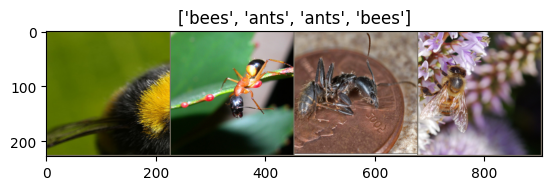

In [ ]:
def imshow(inp, title=None):
    """Display image for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated


# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

# [7] https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

In [ ]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    # Create a temporary directory to save training checkpoints
    with TemporaryDirectory() as tempdir:
        best_model_params_path = os.path.join(tempdir, 'best_model_params.pt')

        torch.save(model.state_dict(), best_model_params_path)
        best_acc = 0.0

        for epoch in range(num_epochs):
            print(f'Epoch {epoch}/{num_epochs - 1}')
            print('-' * 10)

            # Each epoch has a training and validation phase
            for phase in ['train', 'val']:
                if phase == 'train':
                    model.train()  # Set model to training mode
                else:
                    model.eval()   # Set model to evaluate mode

                running_loss = 0.0
                running_corrects = 0

                # Iterate over data.
                for inputs, labels in dataloaders[phase]:
                    inputs = inputs.to(device)
                    labels = labels.to(device)

                    # zero the parameter gradients
                    optimizer.zero_grad()

                    # forward
                    # track history if only in train
                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)

                        # backward + optimize only if in training phase
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()

                    # statistics
                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels.data)
                if phase == 'train':
                    scheduler.step()

                epoch_loss = running_loss / dataset_sizes[phase]
                epoch_acc = running_corrects.double() / dataset_sizes[phase]

                print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

                # deep copy the model
                if phase == 'val' and epoch_acc > best_acc:
                    best_acc = epoch_acc
                    torch.save(model.state_dict(), best_model_params_path)

            print()

        time_elapsed = time.time() - since
        print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
        print(f'Best val Acc: {best_acc:4f}')

        # load best model weights
        model.load_state_dict(torch.load(best_model_params_path, weights_only=True))
    return model

    # [7] https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

In [ ]:
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title(f'predicted: {class_names[preds[j]]}')
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

# [7] https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

In [ ]:
model_conv = torchvision.models.resnet18(weights='IMAGENET1K_V1')
for param in model_conv.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that only parameters of final layer are being optimized as
# opposed to before.
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

# [7] https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

Question 11

In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader, Subset
import numpy as np

transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# CIFAR-10 contains 60,000 32x32 color images in 10 classes
# We will reduce it to only 100 images (e.g., the first 100 images from the training set)
dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)

indices = np.random.choice(len(dataset), size=100, replace=False)
small_dataset = Subset(dataset, indices)

resnet18 = models.resnet18(pretrained=True)
resnet18 = nn.Sequential(*list(resnet18.children())[:-1])
resnet18.eval()

def extract_features(dataset, batch_size=32):
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    features = []

    with torch.no_grad():
        for inputs, _ in dataloader:
            output = resnet18(inputs)
            output = output.view(output.size(0), -1)
            features.append(output.cpu())

    features = torch.cat(features, dim=0)

    return features

train_features = extract_features(small_dataset)

print("Shape of the extracted features:", train_features.shape)

print("Feature vector for the first image:", train_features[0])
#[8] https://youtu.be/WWcgHjuKVqA?si=Us0VbfRwKI4wnTkP


Files already downloaded and verified


/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Shape of the extracted features: torch.Size([100, 512])
Feature vector for the first image: tensor([7.0869e-01, 1.1760e+00, 2.9492e+00, 1.4560e+00, 2.1631e-01, 7.3461e-01,
        1.2583e-01, 1.2004e-01, 1.1508e+00, 1.1477e-01, 1.5271e-02, 1.2613e-01,
        2.2169e+00, 1.9747e-02, 5.1603e-01, 7.0214e-03, 9.1658e-03, 1.1456e-02,
        4.0488e-02, 8.7885e-01, 1.5742e+00, 2.8083e-01, 1.6416e+00, 2.1078e-01,
        1.0323e-01, 3.0233e-03, 1.7642e-01, 8.3369e-01, 1.6653e-02, 3.1982e-02,
        3.0580e+00, 8.5618e-01, 2.8939e-01, 5.4875e-01, 1.7407e+00, 5.2961e-01,
        1.1698e+00, 1.3148e+00, 5.9493e-01, 1.3904e-01, 4.0462e+00, 6.9745e-01,
        2.4387e-01, 2.0392e-01, 1.0338e+00, 2.3047e-01, 2.8740e-01, 1.5549e-01,
        9.6585e-01, 4.7097e-01, 9.4910e-01, 5.2344e-02, 2.2368e+00, 1.0943e+00,
        5.2801e-01, 5.6281e-01, 1.0355e-03, 6.2092e-01, 3.2403e-01, 0.0000e+00,
        7.5815e-01, 8.3843e-01, 8.8429e-02, 1.3207e+00, 5.5442e-01, 4.0515e-01,
        0.0000e+00, 1.8714e-

Question 12

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score

# Load Fashion MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

x_train = x_train[:1000]
y_train = y_train[:1000]
x_test = x_test[:500]
y_test = y_test[:500]

x_train = np.repeat(x_train[..., np.newaxis], 3, axis=-1)
x_test = np.repeat(x_test[..., np.newaxis], 3, axis=-1)
x_train = tf.image.resize(x_train, (64, 64))
x_test = tf.image.resize(x_test, (64, 64))
x_train = preprocess_input(x_train)
x_test = preprocess_input(x_test)

mobilenet_model = MobileNetV2(weights='imagenet', include_top=False, pooling='avg', input_shape=(64, 64, 3))

train_features = mobilenet_model.predict(x_train, batch_size=32)
test_features = mobilenet_model.predict(x_test, batch_size=32)

log_reg = LogisticRegression(penalty='l2', solver='liblinear', max_iter=1000)
log_reg.fit(train_features, y_train)

y_pred_log_reg = log_reg.predict(test_features)
accuracy_log_reg = accuracy_score(y_test, y_pred_log_reg)
f1_log_reg = f1_score(y_test, y_pred_log_reg, average='weighted')

print("Logistic Regression Results:")
print(f"Accuracy: {accuracy_log_reg:.2f}")
print(f"F1 Score: {f1_log_reg:.2f}\n")

rf = RandomForestClassifier(random_state=42)
param_grid_rf = {
    'max_depth': [10, 20, 30],
    'n_estimators': [50, 100]
}
grid_search_rf = GridSearchCV(rf, param_grid_rf, scoring='f1_weighted', cv=3)
grid_search_rf.fit(train_features, y_train)
best_rf = grid_search_rf.best_estimator_

y_pred_rf = best_rf.predict(test_features)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')

print("Random Forest Results:")
print(f"Accuracy: {accuracy_rf:.2f}")
print(f"F1 Score: {f1_rf:.2f}\n")

print("\nBest Random Forest Parameters:")
print(grid_search_rf.best_params_)

#[8]https://youtu.be/WWcgHjuKVqA?si=Us0VbfRwKI4wnTkP
#[9] https://g.co/gemini/share/a985c1f862de
#I learnt how to download a MNIST dataset

<ipython-input-163-5ffe647dd0d8>:27: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenet_model = MobileNetV2(weights='imagenet', include_top=False, pooling='avg', input_shape=(64, 64, 3))


32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 161ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step
Logistic Regression Results:
Accuracy: 0.80
F1 Score: 0.80

Random Forest Results:
Accuracy: 0.77
F1 Score: 0.77


Best Random Forest Parameters:
{'max_depth': 10, 'n_estimators': 100}


In [164]:
#Logistic Regression has greater accuracy and F1 score than Random Forest

Question 13

**Findings and Results**

In [165]:
"""Most important finding was that how the diffreent models give different accuracy results , also how the score data channges when we run the model again, therfore cross validation comes in handy to give consistent accuracy results"""

'Most important finding was that how the diffreent models give different accuracy results , also how the score data channges when we run the model again, therfore cross validation comes in handy to give consistent accuracy results'

**References**

[1] https://g.co/gemini/share/559ae2cf108e
[2] https://youtu.be/gJo0uNL-5Qw?si=7u20UFt97Cs-w5nw
[3]https://youtu.be/HdlDYng8g9s?si=4WftNXMGEYdBmogL
[4]https://youtu.be/5Xh9FusE8iE?si=mwTV0JhYj3v65Bmh
[5]https://chatgpt.com/share/6734e535-b374-8009-bfcc-4ee713d66401
[6] Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. Decision Support Systems, 62, 22–31. https://doi.org/10.1016/j.dss.2014.03.001
[7] https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html
[8] https://youtu.be/WWcgHjuKVqA?si=Us0VbfRwKI4wnTkP
[9] https://g.co/gemini/share/a985c1f862de